> **Reproducibility note.** Rows that are identical in every column except `Booking_ID` (about 28% of the file) are probably group bookings, so by default they are **kept**, and the train/validation/test split is done **by group of identical rows** so that copies of one booking never land on both sides of a split (no leakage).
> Set `DEDUP = True` in the next code cell to run the sensitivity analysis with exact duplicates removed. Re-run the whole notebook after changing it. Numbers quoted in the markdown text below come from the default run (`DEDUP = False`).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

In [3]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
plt.rcParams.update({
    "axes.grid.axis": "y",        # light horizontal grid only
    "grid.color": "#E6E6E6",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# One colour per meaning across the notebook (special requests: 0 / 1 / 2)
REQ_COLORS = ["#C44E52", "#DD9A35", "#3478A8"]
pd.set_option("display.max_columns", 100)

DEDUP = False   # True = sensitivity analysis without exact duplicate rows

df = pd.read_csv("booking.csv")

df["canceled"] = (
    df["booking status"] == "Canceled"
).astype(int)

# Identical bookings (all columns except Booking_ID) share one dup_group id
key_cols = [c for c in df.columns if c not in ("Booking_ID", "canceled")]
df["dup_group"] = df.groupby(key_cols, sort=False).ngroup()

if DEDUP:
    df = df.drop_duplicates(subset=key_cols).reset_index(drop=True)

print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Shape: (36285, 19)


,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status,canceled,dup_group
0,INN00001,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled,0,0
1,INN00002,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled,0,1
2,INN00003,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled,1,2
3,INN00004,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled,1,3
4,INN00005,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled,1,4


,dtype
Booking_ID,object
number of adults,int64
number of children,int64
number of weekend nights,int64
number of week nights,int64
type of meal,object
car parking space,int64
room type,object
lead time,int64
market segment type,object


In [4]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "unique_values": df.nunique()
})

audit["missing_pct"] = (
    audit["missing_n"] / len(df) * 100
)

display(audit.round(2))

print("Duplicated Booking_ID:",
      df["Booking_ID"].duplicated().sum())

print("Duplicated rows excluding ID:",
      df.drop(columns=["Booking_ID"]).duplicated().sum())

print("\nNumerical summary:")
display(
    df.select_dtypes(include="number")
      .drop(columns=["canceled", "dup_group"])
      .describe()
      .T
      .round(2)
)

,dtype,missing_n,unique_values,missing_pct
Booking_ID,object,0,36285,0.0
number of adults,int64,0,5,0.0
number of children,int64,0,6,0.0
number of weekend nights,int64,0,8,0.0
number of week nights,int64,0,18,0.0
type of meal,object,0,4,0.0
car parking space,int64,0,2,0.0
room type,object,0,7,0.0
lead time,int64,0,352,0.0
market segment type,object,0,5,0.0


Duplicated Booking_ID: 0
Duplicated rows excluding ID: 10276

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
number of adults,36285.0,1.84,0.52,0.0,2.0,2.00,2.0,4.0
number of children,36285.0,0.11,0.40,0.0,0.0,0.00,0.0,10.0
number of weekend nights,36285.0,0.81,0.87,0.0,0.0,1.00,2.0,7.0
number of week nights,36285.0,2.20,1.41,0.0,1.0,2.00,3.0,17.0
car parking space,36285.0,0.03,0.17,0.0,0.0,0.00,0.0,1.0
lead time,36285.0,85.24,85.94,0.0,17.0,57.00,126.0,443.0
repeated,36285.0,0.03,0.16,0.0,0.0,0.00,0.0,1.0
P-C,36285.0,0.02,0.37,0.0,0.0,0.00,0.0,13.0
P-not-C,36285.0,0.15,1.75,0.0,0.0,0.00,0.0,58.0
average price,36285.0,103.42,35.09,0.0,80.3,99.45,120.0,540.0


### Duplicate rows: what are they?

Rows identical in every column except `Booking_ID` are not scattered randomly: they form groups (some of them very large) concentrated in the Offline and Corporate segments and among long lead times, which is typical of **group / block bookings**. Without a guest ID we cannot prove this, so the main analysis keeps them and splits the data by group. The `DEDUP` switch in the first code cell reruns everything without them.

In [5]:
group_size = df.groupby("dup_group")["dup_group"].transform("size")
in_dup_group = group_size > 1

print("Largest group of identical bookings:", group_size.max())
print(f"Share of rows in a duplicate group: {in_dup_group.mean():.1%}")

display(
    in_dup_group.groupby(df["market segment type"]).mean().mul(100).round(1)
    .to_frame("% of rows in a duplicate group")
)
display(
    in_dup_group.groupby(df["canceled"]).mean().mul(100).round(1)
    .to_frame("% of rows in a duplicate group")
)

Largest group of identical bookings: 91
Share of rows in a duplicate group: 37.0%


,% of rows in a duplicate group
market segment type,
Aviation,31.2
Complementary,16.1
Corporate,41.2
Offline,70.0
Online,22.0


,% of rows in a duplicate group
canceled,
0,32.5
1,46.2


# initial EDA analysis

,status,count,percentage
0,Not_Canceled,24396,67.23
1,Canceled,11889,32.77


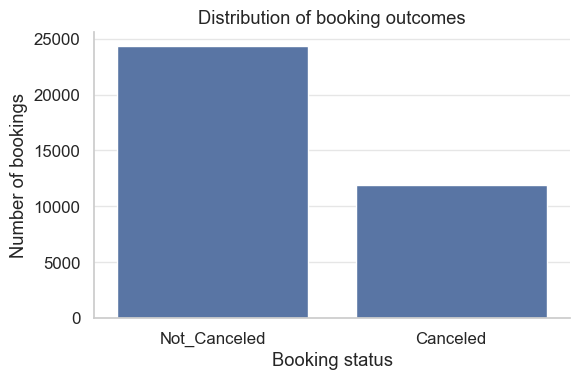

In [6]:
target_summary = (
    df["booking status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

target_summary["percentage"] = (
    target_summary["count"] / len(df) * 100
)

display(target_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 4))

sns.countplot(
    data=df,
    x="booking status",
    order=["Not_Canceled", "Canceled"],
    ax=ax
)

ax.set_title("Distribution of booking outcomes")
ax.set_xlabel("Booking status")
ax.set_ylabel("Number of bookings")

plt.tight_layout()
plt.show()

In [7]:
categorical_features = [
    "type of meal",
    "room type",
    "market segment type",
    "car parking space",
    "repeated"
]

categorical_results = []

for feature in categorical_features:
    summary = (
        df.groupby(feature, dropna=False)
        .agg(
            bookings=("canceled", "size"),
            cancellations=("canceled", "sum"),
            cancellation_rate=("canceled", "mean")
        )
        .reset_index()
        .rename(columns={feature: "category"})
    )

    summary["feature"] = feature
    summary["share_of_bookings"] = (
        summary["bookings"] / len(df) * 100
    )
    summary["cancellation_rate"] *= 100

    categorical_results.append(summary)

categorical_screening = pd.concat(
    categorical_results,
    ignore_index=True
)

display(
    categorical_screening[
        [
            "feature",
            "category",
            "bookings",
            "share_of_bookings",
            "cancellations",
            "cancellation_rate"
        ]
    ]
    .sort_values(["feature", "bookings"],
                 ascending=[True, False])
    .round(2)
)

,feature,category,bookings,share_of_bookings,cancellations,cancellation_rate
16,car parking space,0,35161,96.90,11775,33.49
17,car parking space,1,1124,3.10,114,10.14
15,market segment type,Online,23221,64.00,8478,36.51
14,market segment type,Offline,10531,29.02,3154,29.95
13,market segment type,Corporate,2017,5.56,220,10.91
12,market segment type,Complementary,391,1.08,0,0.00
11,market segment type,Aviation,125,0.34,37,29.60
18,repeated,0,35355,97.44,11873,33.58
19,repeated,1,930,2.56,16,1.72
4,room type,Room_Type 1,28138,77.55,9076,32.26


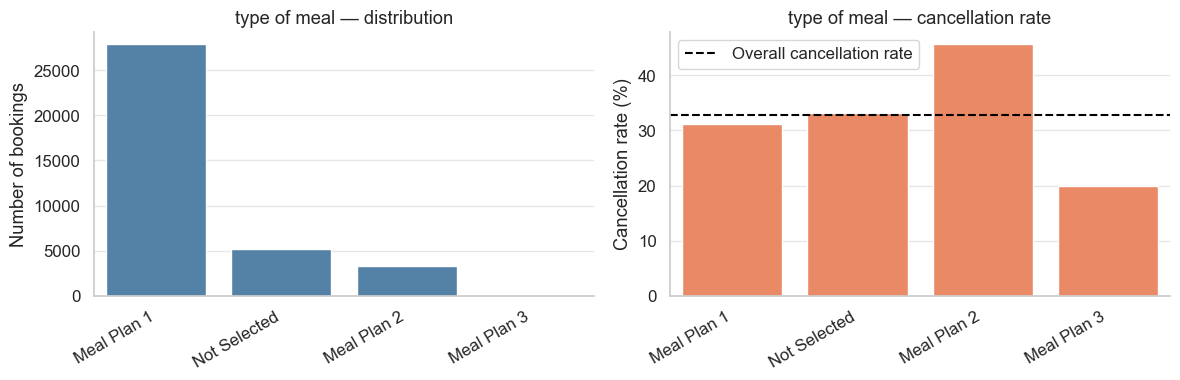

,bookings,cancellation_rate
type of meal,,
Meal Plan 1,27842,31.18
Not Selected,5132,33.13
Meal Plan 2,3306,45.58
Meal Plan 3,5,20.00


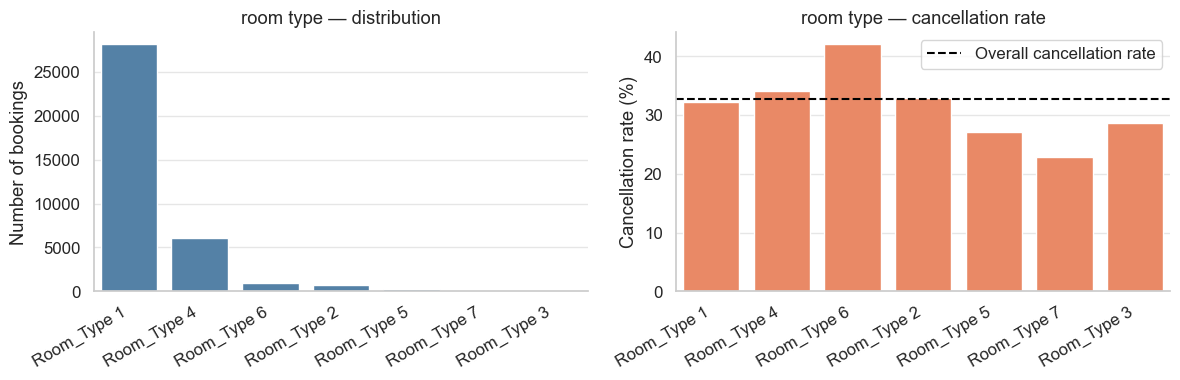

,bookings,cancellation_rate
room type,,
Room_Type 1,28138,32.26
Room_Type 4,6059,34.15
Room_Type 6,966,42.03
Room_Type 2,692,32.95
Room_Type 5,265,27.17
Room_Type 7,158,22.78
Room_Type 3,7,28.57


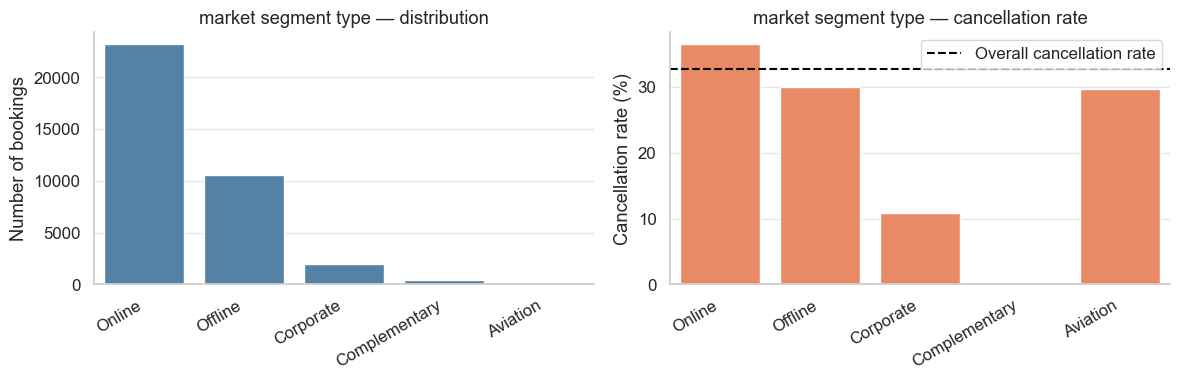

,bookings,cancellation_rate
market segment type,,
Online,23221,36.51
Offline,10531,29.95
Corporate,2017,10.91
Complementary,391,0.00
Aviation,125,29.60


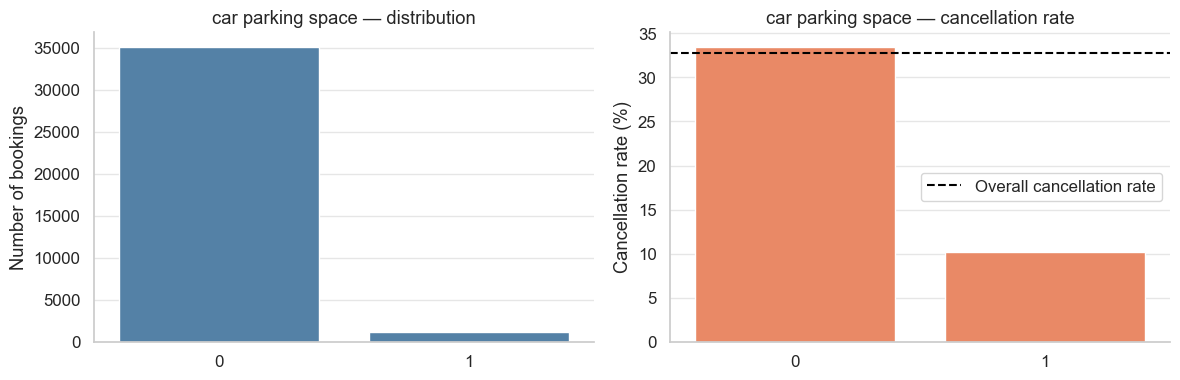

,bookings,cancellation_rate
car parking space,,
0,35161,33.49
1,1124,10.14


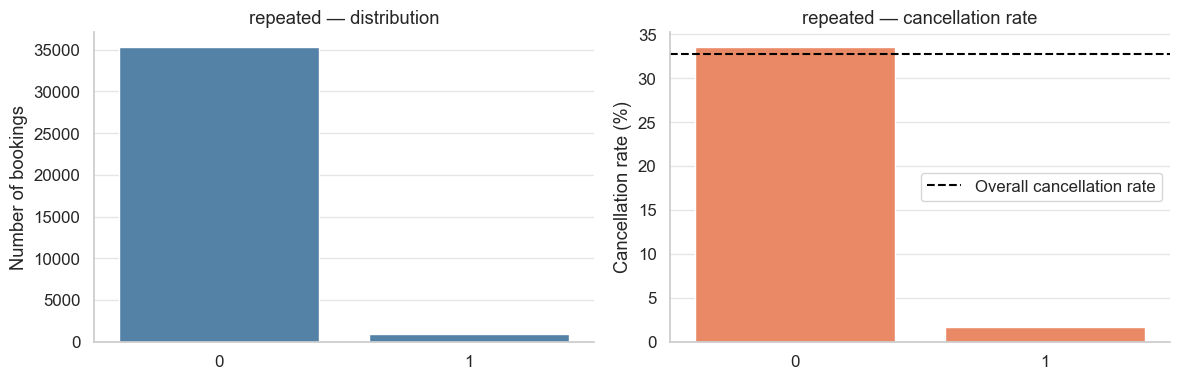

,bookings,cancellation_rate
repeated,,
0,35355,33.58
1,930,1.72


In [8]:
categorical_features = [
    "type of meal",
    "room type",
    "market segment type",
    "car parking space",
    "repeated"
]

for feature in categorical_features:

    summary = (
        df.groupby(feature, dropna=False)
        .agg(
            bookings=("canceled", "size"),
            cancellation_rate=("canceled", "mean")
        )
        .sort_values("bookings", ascending=False)
    )

    summary["cancellation_rate"] *= 100

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.barplot(
        x=summary.index.astype(str),
        y=summary["bookings"],
        ax=axes[0],
        color="steelblue"
    )

    axes[0].set_title(f"{feature} — distribution")
    axes[0].set_ylabel("Number of bookings")
    axes[0].set_xlabel("")

    sns.barplot(
        x=summary.index.astype(str),
        y=summary["cancellation_rate"],
        ax=axes[1],
        color="coral"
    )

    axes[1].axhline(
        df["canceled"].mean() * 100,
        color="black",
        linestyle="--",
        label="Overall cancellation rate"
    )

    axes[1].set_title(f"{feature} — cancellation rate")
    axes[1].set_ylabel("Cancellation rate (%)")
    axes[1].set_xlabel("")
    axes[1].legend()

    # Tilt x labels only when they are long (e.g. "Room_Type 1"); keep 0/1 flat
    for ax in axes:
        longest = max((len(t.get_text()) for t in ax.get_xticklabels()), default=0)
        if longest > 6:
            plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

    plt.tight_layout()
    plt.show()

    display(
        summary.assign(
            cancellation_rate=summary["cancellation_rate"].round(2)
        )
    )

In [9]:
results = []

for feature in categorical_features:

    rates = (
        df.groupby(feature, dropna=False)["canceled"]
        .agg(["mean", "size"])
    )

    rates = rates[rates["size"] >= 100]

    if len(rates) < 2:
        continue

    results.append({
        "feature": feature,
        "min_rate": rates["mean"].min() * 100,
        "max_rate": rates["mean"].max() * 100,
        "difference_pp": (
            rates["mean"].max() - rates["mean"].min()
        ) * 100
    })

comparison = (
    pd.DataFrame(results)
    .sort_values("difference_pp", ascending=False)
)

display(comparison.round(2))

,feature,min_rate,max_rate,difference_pp
2,market segment type,0.00,36.51,36.51
4,repeated,1.72,33.58,31.86
3,car parking space,10.14,33.49,23.35
1,room type,22.78,42.03,19.24
0,type of meal,31.18,45.58,14.40


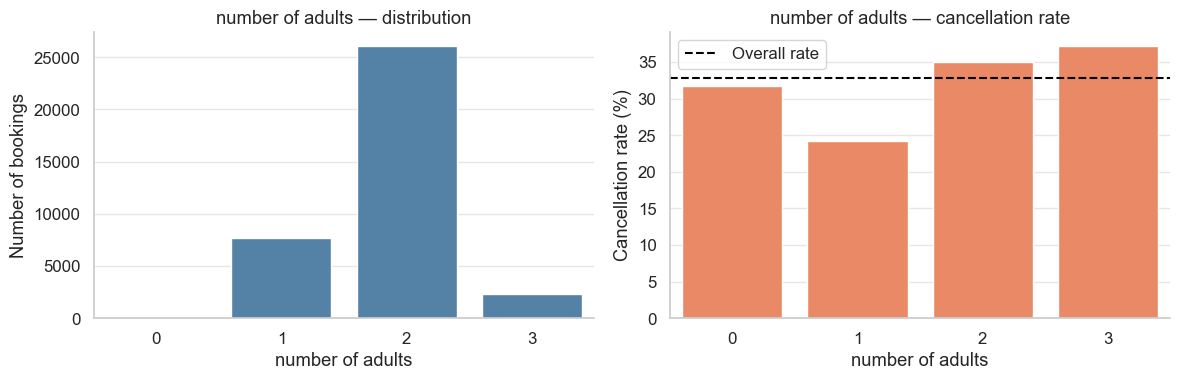

,bookings,cancellation_rate
number of adults,,
0,139,31.65
1,7702,24.14
2,26110,34.93
3,2318,37.23
4,16,18.75


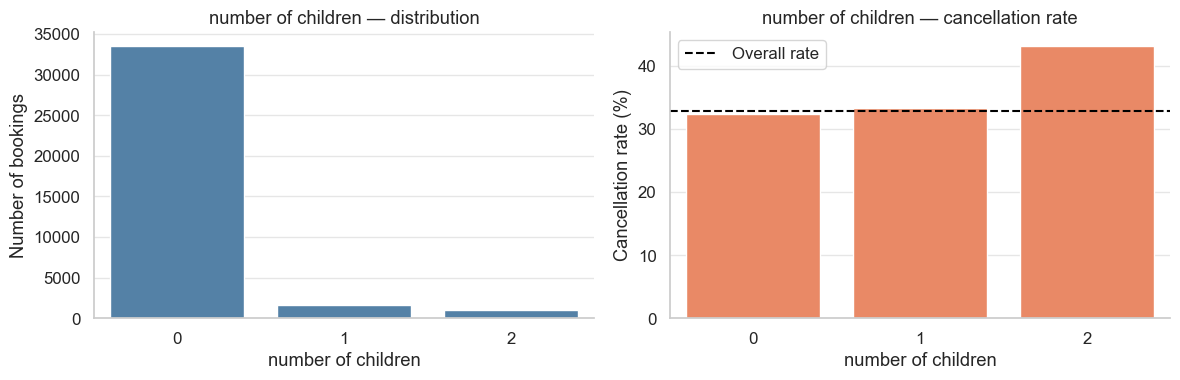

,bookings,cancellation_rate
number of children,,
0,33583,32.41
1,1622,33.35
2,1058,43.19
3,19,26.32
9,2,50.00
10,1,0.00


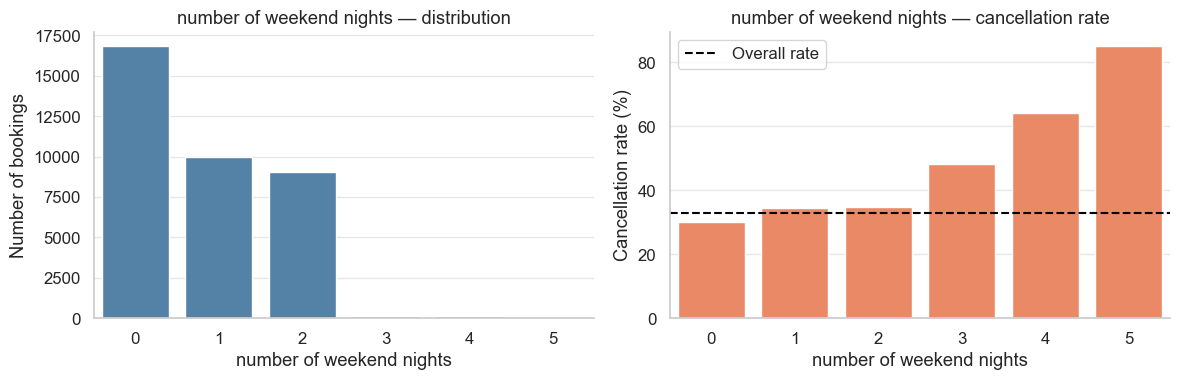

,bookings,cancellation_rate
number of weekend nights,,
0,16876,30.19
1,10000,34.34
2,9072,34.80
3,153,48.37
4,129,64.34
5,34,85.29
6,20,80.00
7,1,100.00


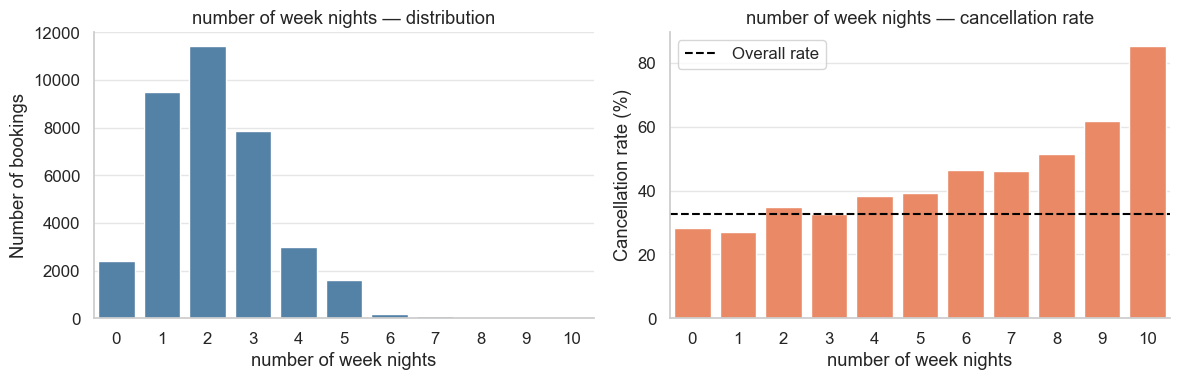

,bookings,cancellation_rate
number of week nights,,
0,2387,28.45
1,9488,27.11
2,11447,34.94
3,7842,32.84
4,2992,38.20
5,1616,39.11
6,189,46.56
7,113,46.02
8,62,51.61


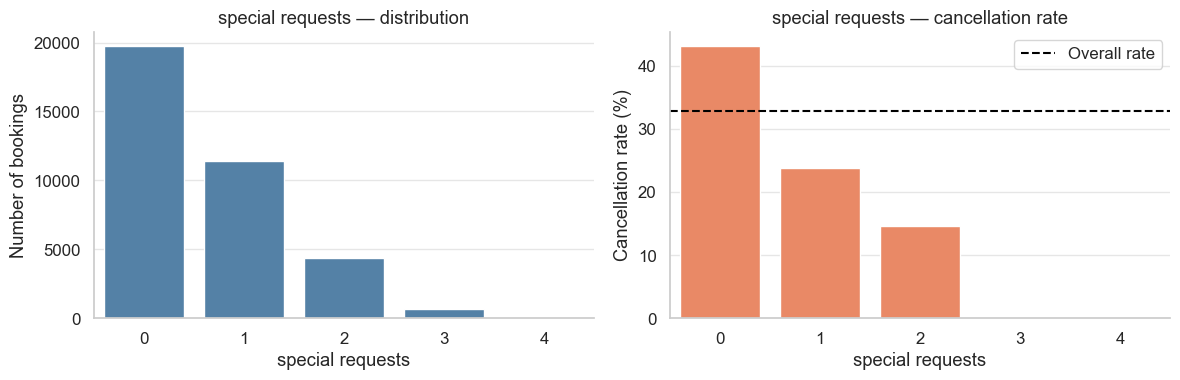

,bookings,cancellation_rate
special requests,,
0,19780,43.21
1,11379,23.77
2,4364,14.60
3,676,0.00
4,78,0.00
5,8,0.00


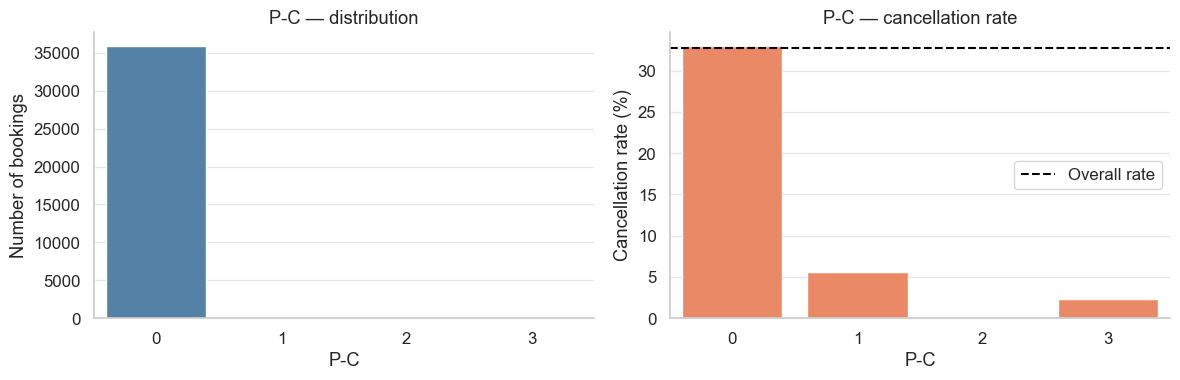

,bookings,cancellation_rate
P-C,,
0,35947,33.03
1,198,5.56
2,46,0.00
3,43,2.33
4,10,0.00
5,11,0.00
6,1,0.00
11,25,0.00
13,4,100.00


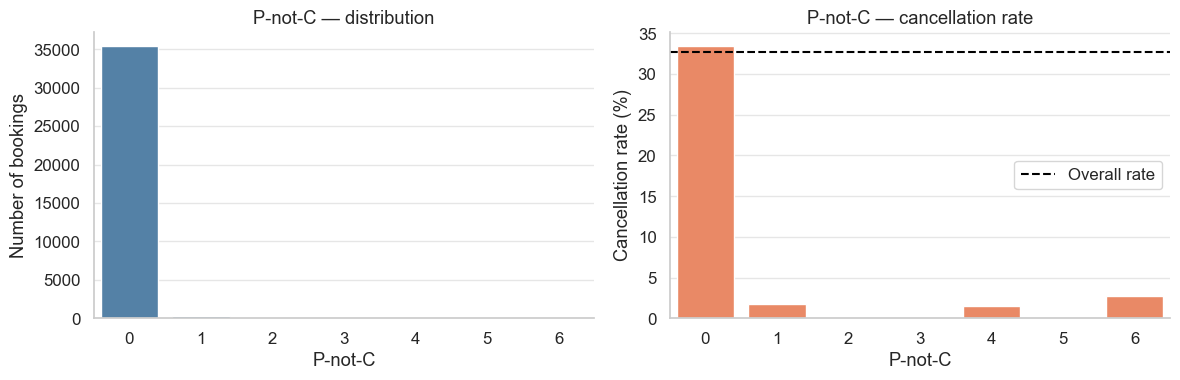

,bookings,cancellation_rate
P-not-C,,
0,35473,33.50
1,228,1.75
2,112,0.00
3,80,0.00
4,65,1.54
5,60,0.00
6,36,2.78
7,24,0.00
8,23,0.00


In [10]:
discrete_features = [
    "number of adults",
    "number of children",
    "number of weekend nights",
    "number of week nights",
    "special requests",
    "P-C",
    "P-not-C"
]

for feature in discrete_features:

    summary = (
        df.groupby(feature)["canceled"]
        .agg(bookings="size", cancellation_rate="mean")
        .sort_index()
    )

    summary["cancellation_rate"] *= 100

    # Show common values separately; keep rare values in a table
    common_values = summary[summary["bookings"] >= 30]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.barplot(
        x=common_values.index.astype(str),
        y=common_values["bookings"],
        color="steelblue",
        ax=axes[0]
    )

    axes[0].set_title(f"{feature} — distribution")
    axes[0].set_ylabel("Number of bookings")
    axes[0].set_xlabel(feature)

    sns.barplot(
        x=common_values.index.astype(str),
        y=common_values["cancellation_rate"],
        color="coral",
        ax=axes[1]
    )

    axes[1].axhline(
        df["canceled"].mean() * 100,
        color="black",
        linestyle="--",
        label="Overall rate"
    )

    axes[1].set_title(f"{feature} — cancellation rate")
    axes[1].set_ylabel("Cancellation rate (%)")
    axes[1].set_xlabel(feature)
    axes[1].legend()

    # Tilt x labels only when they are long (e.g. "Room_Type 1"); keep 0/1 flat
    for ax in axes:
        longest = max((len(t.get_text()) for t in ax.get_xticklabels()), default=0)
        if longest > 6:
            plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

    plt.tight_layout()
    plt.show()

    display(summary.round(2))

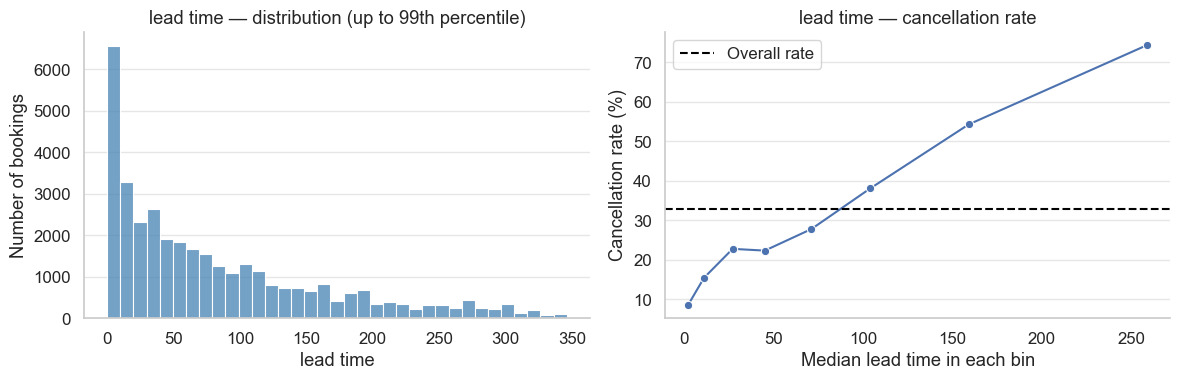

,bin,bookings,cancellation_rate,median_value
0,"(-0.001, 5.0]",4855,8.49,2.0
1,"(5.0, 17.0]",4373,15.44,11.0
2,"(17.0, 35.0]",4452,22.75,27.0
3,"(35.0, 57.0]",4527,22.31,45.0
4,"(57.0, 86.0]",4540,27.75,71.0
5,"(86.0, 126.0]",4477,38.06,104.0
6,"(126.0, 192.0]",4587,54.24,159.0
7,"(192.0, 443.0]",4474,74.36,259.0


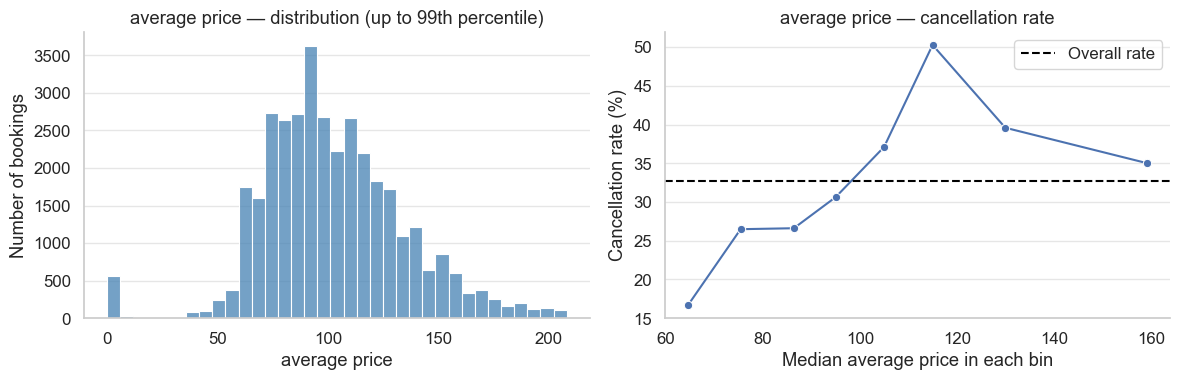

,bin,bookings,cancellation_rate,median_value
0,"(-0.001, 70.0]",4560,16.67,64.56
1,"(70.0, 80.3]",4527,26.49,75.42
2,"(80.3, 90.0]",4814,26.61,86.40
3,"(90.0, 99.45]",4269,30.62,95.00
4,"(99.45, 109.65]",4517,37.10,105.00
5,"(109.65, 120.0]",4539,50.28,115.00
6,"(120.0, 140.4]",4656,39.58,130.00
7,"(140.4, 540.0]",4403,35.00,159.30


In [11]:
continuous_features = [
    "lead time",
    "average price"
]

for feature in continuous_features:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Distribution, with extreme values hidden only on the plot
    upper = df[feature].quantile(0.99)

    sns.histplot(
        data=df[df[feature] <= upper],
        x=feature,
        bins=35,
        color="steelblue",
        ax=axes[0]
    )

    axes[0].set_title(f"{feature} — distribution (up to 99th percentile)")
    axes[0].set_ylabel("Number of bookings")

    # Equal-frequency bins for cancellation rate
    temp = df[[feature, "canceled"]].copy()

    temp["bin"] = pd.qcut(
        temp[feature],
        q=8,
        duplicates="drop"
    )

    summary = (
        temp.groupby("bin", observed=True)
        .agg(
            bookings=("canceled", "size"),
            cancellation_rate=("canceled", "mean"),
            median_value=(feature, "median")
        )
        .reset_index()
    )

    summary["cancellation_rate"] *= 100

    sns.lineplot(
        data=summary,
        x="median_value",
        y="cancellation_rate",
        marker="o",
        ax=axes[1]
    )

    axes[1].axhline(
        df["canceled"].mean() * 100,
        color="black",
        linestyle="--",
        label="Overall rate"
    )

    axes[1].set_title(f"{feature} — cancellation rate")
    axes[1].set_xlabel(f"Median {feature} in each bin")
    axes[1].set_ylabel("Cancellation rate (%)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    display(summary.round(2))

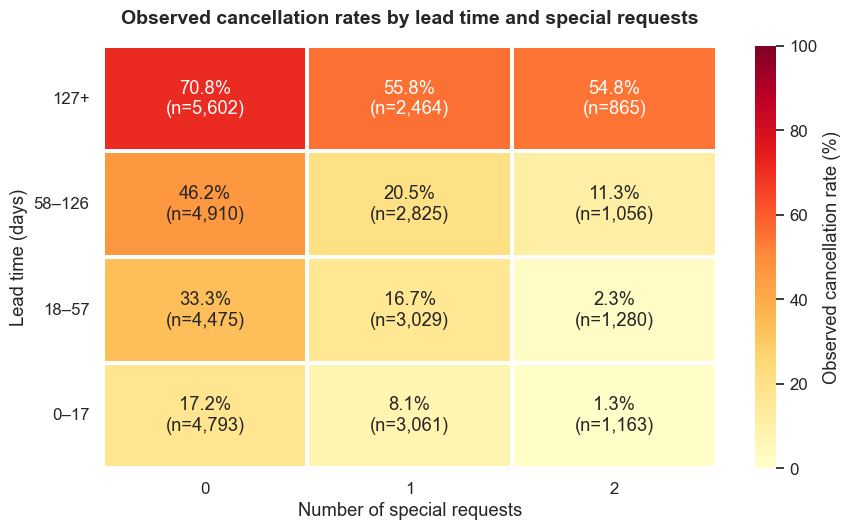

In [12]:

# EDA: Lead time × special requests × cancellation

eda_interaction = df[df["special requests"].isin([0, 1, 2])].copy()

lead_bins = [-1, 17, 57, 126, np.inf]
lead_labels = ["0–17", "18–57", "58–126", "127+"]

eda_interaction["lead_group"] = pd.cut(
    eda_interaction["lead time"],
    bins=lead_bins,
    labels=lead_labels
)

interaction_summary = (
    eda_interaction.groupby(
        ["lead_group", "special requests"],
        observed=True
    )
    .agg(
        n=("canceled", "size"),
        cancellation_rate=("canceled", "mean")
    )
    .reset_index()
)

interaction_summary["cancellation_rate"] *= 100

rates = (
    interaction_summary.pivot(
        index="lead_group",
        columns="special requests",
        values="cancellation_rate"
    )
    .reindex(index=lead_labels, columns=[0, 1, 2])
)

counts = (
    interaction_summary.pivot(
        index="lead_group",
        columns="special requests",
        values="n"
    )
    .reindex(index=lead_labels, columns=[0, 1, 2])
)

annotations = rates.copy().astype(object)

for i in range(len(rates.index)):
    for j in range(len(rates.columns)):
        rate = rates.iloc[i, j]
        n = counts.iloc[i, j]

        annotations.iloc[i, j] = (
            f"{rate:.1f}%\n(n={int(n):,})"
            if pd.notna(rate) else "No data"
        )

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.heatmap(
    rates,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=1.5,
    linecolor="white",
    cbar_kws={
        "label": "Observed cancellation rate (%)"
    },
    ax=ax
)

ax.set_title(
    "Observed cancellation rates by lead time and special requests",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Number of special requests")
ax.set_ylabel("Lead time (days)")

# Display the longest booking lead times at the top
ax.invert_yaxis()

ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


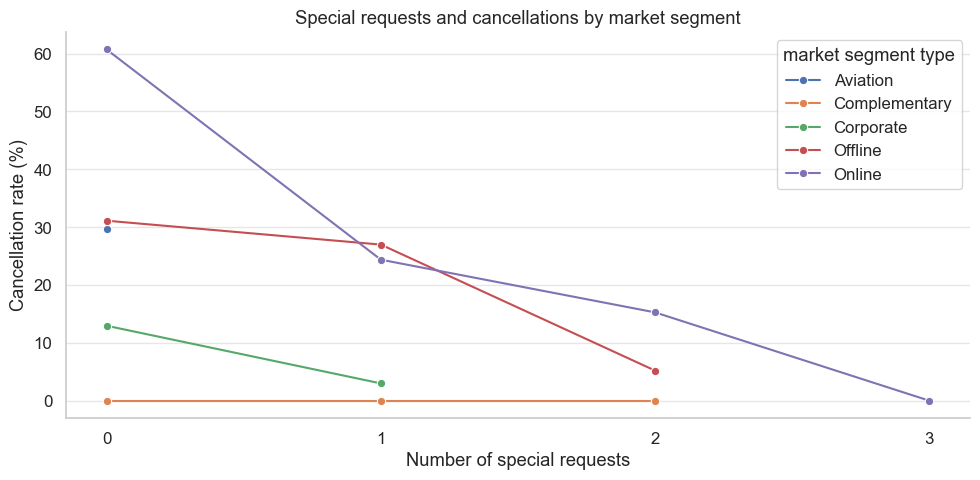

,market segment type,special requests,bookings,rate
0,Aviation,0,125,29.60
1,Complementary,0,167,0.00
2,Complementary,1,144,0.00
3,Complementary,2,50,0.00
6,Corporate,0,1613,12.96
7,Corporate,1,368,2.99
10,Offline,0,8622,31.12
11,Offline,1,1712,26.99
12,Offline,2,173,5.20
16,Online,0,9253,60.72


In [13]:
segment_requests = (
    df.groupby(
        ["market segment type", "special requests"]
    )
    .agg(
        bookings=("canceled", "size"),
        rate=("canceled", "mean")
    )
    .reset_index()
)

segment_requests = segment_requests[
    (segment_requests["special requests"] <= 3)
    & (segment_requests["bookings"] >= 30)
].copy()

segment_requests["rate"] *= 100

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=segment_requests,
    x="special requests",
    y="rate",
    hue="market segment type",
    marker="o",
    ax=ax
)

ax.set_title("Special requests and cancellations by market segment")
ax.set_xlabel("Number of special requests")
ax.set_ylabel("Cancellation rate (%)")
ax.set_xticks([0, 1, 2, 3])

plt.tight_layout()
plt.show()

display(segment_requests.round(2))

In [14]:
raw_dates = df["date of reservation"].astype(str)

dates = pd.to_datetime(
    raw_dates,
    format="%m/%d/%Y",
    errors="coerce"
)

print("Unparsed dates:", dates.isna().sum())

display(
    df.loc[
        dates.isna(),
        ["date of reservation", "booking status"]
    ].head(20)
)

print("\nYears:")
display(dates.dt.year.value_counts(dropna=False).sort_index())

print("\nDate range:")
print(dates.min(), "to", dates.max())

Unparsed dates: 37


,date of reservation,booking status
2626,2018-2-29,Canceled
3677,2018-2-29,Canceled
5600,2018-2-29,Not_Canceled
6343,2018-2-29,Not_Canceled
7648,2018-2-29,Canceled
8000,2018-2-29,Not_Canceled
8989,2018-2-29,Not_Canceled
9153,2018-2-29,Not_Canceled
9245,2018-2-29,Not_Canceled
9664,2018-2-29,Not_Canceled



Years:


date of reservation
2015.0        1
2016.0        1
2017.0     6516
2018.0    29730
NaN          37
Name: count, dtype: int64


Date range:
2015-10-02 00:00:00 to 2018-12-31 00:00:00


In [15]:
requests_profile = (
    df.groupby("special requests")
    .agg(
        bookings=("canceled", "size"),
        cancellation_rate=("canceled", "mean"),
        median_lead_time=("lead time", "median"),
        median_price=("average price", "median"),
        repeated_share=("repeated", "mean"),
        online_share=(
            "market segment type",
            lambda x: (x == "Online").mean()
        )
    )
)

for col in ["cancellation_rate", "repeated_share", "online_share"]:
    requests_profile[col] *= 100

display(requests_profile.round(2))

,bookings,cancellation_rate,median_lead_time,median_price,repeated_share,online_share
special requests,,,,,,
0,19780,43.21,65.0,95.00,2.69,46.78
1,11379,23.77,52.0,103.00,2.73,80.46
2,4364,14.60,47.0,114.40,1.35,94.25
3,676,0.00,53.5,116.16,2.66,93.05
4,78,0.00,53.0,120.00,12.82,82.05
5,8,0.00,30.0,96.60,0.00,87.50


,lead_time_group,repeated,bookings,cancellation_rate
0,0–17,0,8467,12.84
1,0–17,1,761,0.00
2,18–57,0,8853,22.81
3,18–57,1,126,3.17
4,58–126,0,8988,32.97
5,58–126,1,29,3.45
6,127+,0,9047,64.15
7,127+,1,14,78.57


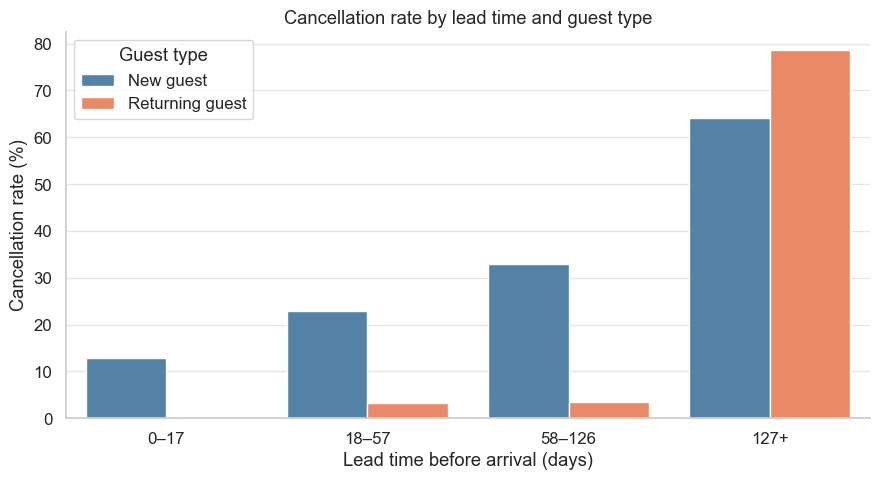

<Figure size 640x480 with 0 Axes>

In [16]:
temp = df.copy()

temp["lead_time_group"] = pd.cut(
    temp["lead time"],
    bins=[-1, 17, 57, 126, np.inf],
    labels=["0–17", "18–57", "58–126", "127+"]
)

repeated_summary = (
    temp.groupby(["lead_time_group", "repeated"], observed=True)
    .agg(
        bookings=("canceled", "size"),
        cancellation_rate=("canceled", "mean")
    )
    .reset_index()
)

repeated_summary["cancellation_rate"] *= 100

display(repeated_summary.round(2))

# Readable labels for returning guest status
repeated_summary["guest_type"] = repeated_summary["repeated"].map({
    0: "New guest",
    1: "Returning guest"
})

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=repeated_summary,
    x="lead_time_group",
    y="cancellation_rate",
    hue="guest_type",
    hue_order=["New guest", "Returning guest"],
    palette={
        "New guest": "steelblue",
        "Returning guest": "coral"
    },
    ax=ax
)

ax.set_title("Cancellation rate by lead time and guest type")
ax.set_xlabel("Lead time before arrival (days)")
ax.set_ylabel("Cancellation rate (%)")

ax.legend(title="Guest type")

plt.tight_layout()
plt.show()

sns.barplot(
    data=repeated_summary,
    x="lead_time_group",
    y="cancellation_rate",
    hue="repeated",
    ax=ax
)

ax.set_title("Cancellation rate by lead time and returning guest status")
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Cancellation rate (%)")
ax.legend(title="Returning guest", labels=["No", "Yes"])

plt.tight_layout()
plt.show()

In [17]:
high_requests = df[df["special requests"] >= 3]

print("Bookings with 3+ requests:", len(high_requests))
print("Cancellations:", high_requests["canceled"].sum())

display(
    high_requests.groupby(
        ["special requests", "market segment type"]
    )["canceled"]
    .agg(["size", "sum", "mean"])
)

Bookings with 3+ requests: 762
Cancellations: 0


size  sum  mean
special requests market segment type                 
3                Complementary          19    0   0.0
                 Corporate               8    0   0.0
                 Offline                20    0   0.0
                 Online                629    0   0.0
4                Complementary          11    0   0.0
                 Offline                 3    0   0.0
                 Online                 64    0   0.0
5                Offline                 1    0   0.0
                 Online                  7    0   0.0

,lead_time_group,special requests,bookings,cancellation_rate
0,0–17,0,2339,26.89
1,0–17,1,2424,10.07
2,0–17,2,1046,1.34
3,18–57,0,2271,60.11
4,18–57,1,2627,19.19
5,18–57,2,1240,2.34
6,58–126,0,2316,66.80
7,58–126,1,2396,23.21
8,58–126,2,1014,11.64
9,127+,0,2327,89.26


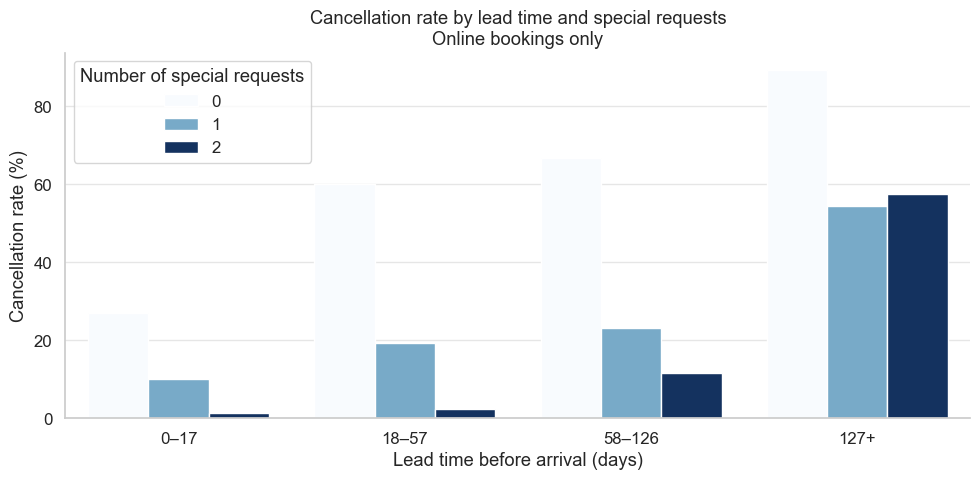

In [18]:
online = df[
    (df["market segment type"] == "Online") &
    (df["special requests"] <= 2)
].copy()

online["lead_time_group"] = pd.cut(
    online["lead time"],
    bins=[-1, 17, 57, 126, np.inf],
    labels=["0–17", "18–57", "58–126", "127+"]
)

online_summary = (
    online.groupby(
        ["lead_time_group", "special requests"],
        observed=True
    )
    .agg(
        bookings=("canceled", "size"),
        cancellation_rate=("canceled", "mean")
    )
    .reset_index()
)

online_summary["cancellation_rate"] *= 100

display(online_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=online_summary,
    x="lead_time_group",
    y="cancellation_rate",
    hue="special requests",
    hue_order=[0, 1, 2],
    palette="Blues",
    ax=ax
)

ax.set_title(
    "Cancellation rate by lead time and special requests\n"
    "Online bookings only"
)
ax.set_xlabel("Lead time before arrival (days)")
ax.set_ylabel("Cancellation rate (%)")
ax.legend(title="Number of special requests")

plt.tight_layout()
plt.show()

# Research hypotheses

Based on the exploratory data analysis (EDA), we formulated four hypotheses concerning the factors associated with hotel booking cancellations:

**H1 - Booking lead time**  
The longer the booking lead time, the higher the probability of cancellation.

**H2 - Special requests**  
Bookings with more special requests have a lower probability of cancellation, even after accounting for other booking characteristics.

**H3 - Interaction between lead time and special requests**  
The relationship between the number of special requests and cancellation risk varies depending on booking lead time.

**H4 - Market segment**  
Market segment is associated with cancellation probability, even after accounting for other booking characteristics.

(These hypotheses will be investigated using the CatBoost model and visualizations of its predictions.)


# More in-depth EDA for variables which will be analyzed further (to be used in presentation)

## H1 - Booking lead time

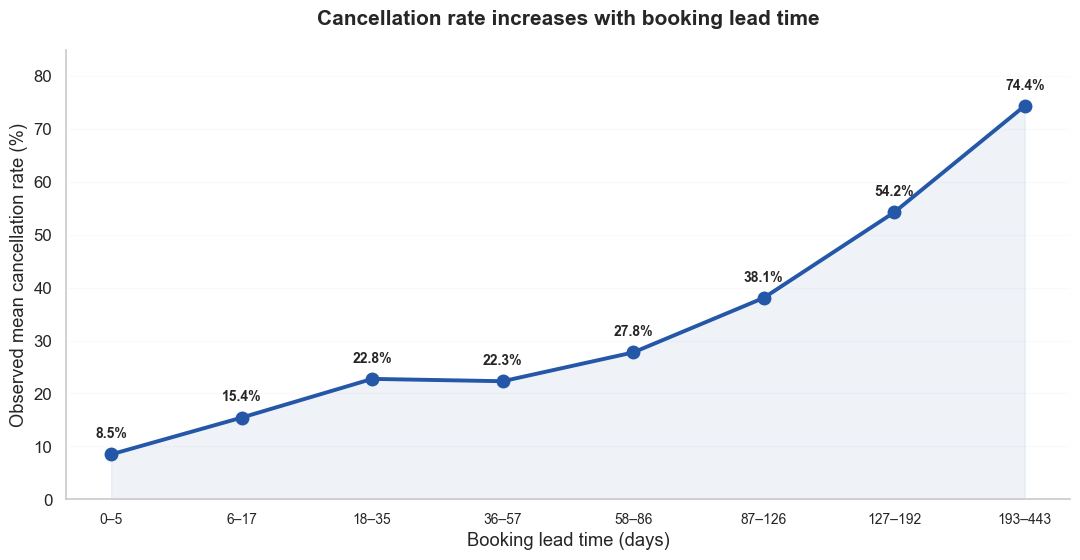

,label,n,cancellation_rate
0,0–5,4855,8.49
1,6–17,4373,15.44
2,18–35,4452,22.75
3,36–57,4527,22.31
4,58–86,4540,27.75
5,87–126,4477,38.06
6,127–192,4587,54.24
7,193–443,4474,74.36


In [19]:
h1_eda = df[["lead time", "canceled"]].copy()

h1_eda["lead_bin"] = pd.qcut(
    h1_eda["lead time"],
    q=8,
    duplicates="drop"
)

summary = (
    h1_eda.groupby("lead_bin", observed=True)
    .agg(
        n=("canceled", "size"),
        cancellation_rate=("canceled", "mean"),
        min_days=("lead time", "min"),
        max_days=("lead time", "max")
    )
    .reset_index()
)

summary["cancellation_rate"] *= 100
summary["label"] = (
    summary["min_days"].astype(str)
    + "–"
    + summary["max_days"].astype(str)
)

fig, ax = plt.subplots(figsize=(11, 5.8))

x = np.arange(len(summary))
rates = summary["cancellation_rate"].to_numpy()

ax.plot(
    x, rates,
    color="#2457A7",
    linewidth=2.8,
    marker="o",
    markersize=9
)

ax.fill_between(x, rates, 0, color="#2457A7", alpha=0.07)

for i, row in summary.iterrows():
    ax.annotate(
        f"{row['cancellation_rate']:.1f}%",
        (i, row["cancellation_rate"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(summary["label"], fontsize=10)

ax.set_title(
    "Cancellation rate increases with booking lead time",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Booking lead time (days)")
ax.set_ylabel("Observed mean cancellation rate (%)")
ax.set_ylim(0, 85)

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

display(summary[["label", "n", "cancellation_rate"]].round(2))


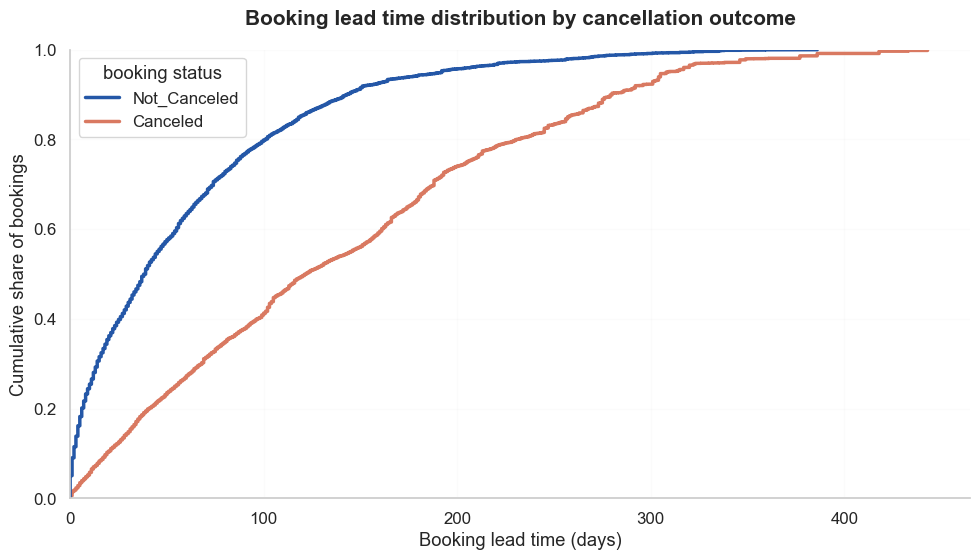

                count  median   mean
booking status                      
Canceled        11889   122.0  139.2
Not_Canceled    24396    39.0   58.9


In [20]:
fig, ax = plt.subplots(figsize=(10, 5.8))

sns.ecdfplot(
    data=df,
    x="lead time",
    hue="booking status",
    palette={
        "Canceled": "#D97961",
        "Not_Canceled": "#2457A7"
    },
    linewidth=2.5,
    ax=ax
)

ax.set_title(
    "Booking lead time distribution by cancellation outcome",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Booking lead time (days)")
ax.set_ylabel("Cumulative share of bookings")

ax.set_xlim(left=0)
ax.grid(alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(
    df.groupby("booking status")["lead time"]
    .agg(["count", "median", "mean"])
    .round(1)
)


/var/folders/wj/mlk3cvns0956mgfq2b8dn78c0000gn/T/ipykernel_14130/1696726040.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/wj/mlk3cvns0956mgfq2b8dn78c0000gn/T/ipykernel_14130/1696726040.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Not canceled", "Canceled"])


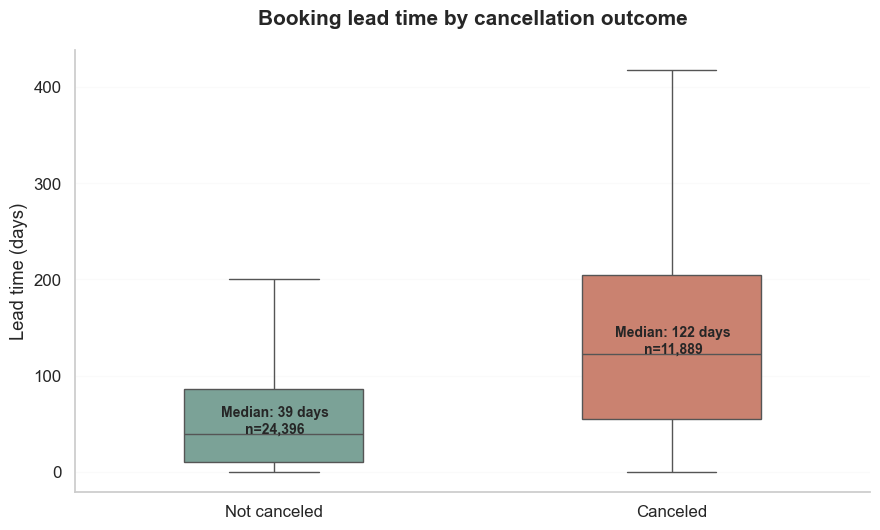

,count,median
booking status,,
Not_Canceled,24396,39.0
Canceled,11889,122.0


In [21]:

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.boxplot(
    data=df,
    x="booking status",
    y="lead time",
    order=["Not_Canceled", "Canceled"],
    palette=["#74A89A", "#D97961"],
    width=0.45,
    showfliers=False,
    ax=ax
)

# Group medians and sample sizes
stats = (
    df.groupby("booking status")["lead time"]
    .agg(["count", "median"])
    .reindex(["Not_Canceled", "Canceled"])
)

for i, (_, row) in enumerate(stats.iterrows()):
    ax.annotate(
        f"Median: {row['median']:.0f} days\nn={int(row['count']):,}",
        (i, row["median"]),
        xytext=(1, 1),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Booking lead time by cancellation outcome",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("")
ax.set_ylabel("Lead time (days)")
ax.set_xticklabels(["Not canceled", "Canceled"])

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

display(stats)


## H2 - Special requests

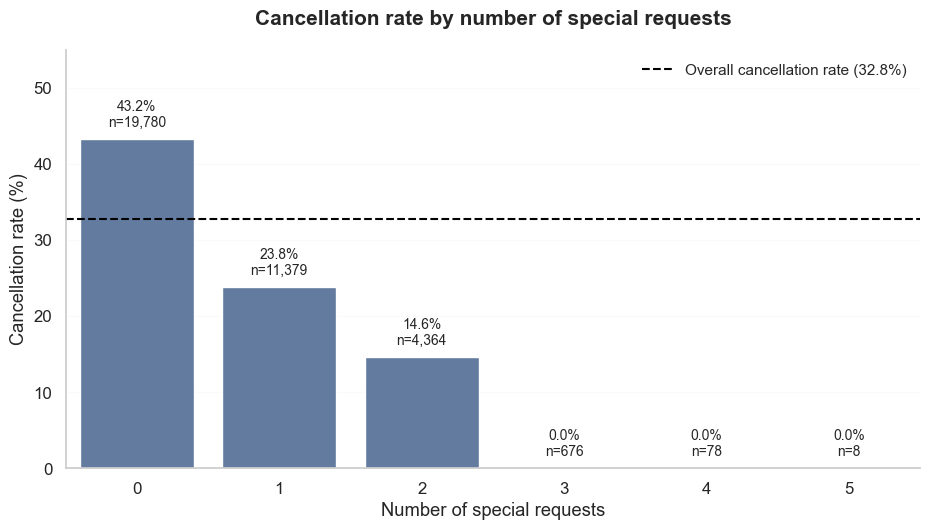

In [22]:

summary = (
    df.groupby("special requests")
    .agg(
        bookings=("canceled", "size"),
        cancellation_rate=("canceled", "mean")
    )
    .reset_index()
)

summary["cancellation_rate"] *= 100
overall_rate = df["canceled"].mean() * 100

fig, ax = plt.subplots(figsize=(9.5, 5.5))

sns.barplot(
    data=summary,
    x="special requests",
    y="cancellation_rate",
    color="#5879A9",
    ax=ax
)

ax.axhline(
    overall_rate,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall cancellation rate ({overall_rate:.1f}%)"
)

for i, row in summary.iterrows():
    ax.annotate(
        f"{row['cancellation_rate']:.1f}%\nn={int(row['bookings']):,}",
        (i, row["cancellation_rate"]),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Cancellation rate by number of special requests",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Number of special requests")
ax.set_ylabel("Cancellation rate (%)")
ax.set_ylim(0, 55)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=11
)

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


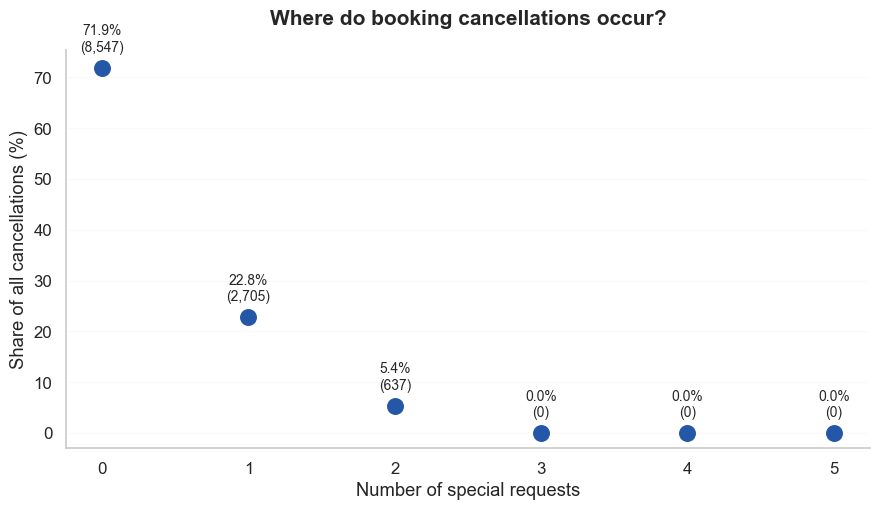

In [23]:

requests_summary = (
    df.groupby("special requests")
    .agg(
        bookings=("canceled", "size"),
        cancellations=("canceled", "sum")
    )
    .reset_index()
)

requests_summary["share_of_cancellations"] = (
    requests_summary["cancellations"]
    / requests_summary["cancellations"].sum() * 100
)

fig, ax = plt.subplots(figsize=(9, 5.3))

ax.scatter(
    requests_summary["special requests"],
    requests_summary["share_of_cancellations"],
    s=125,
    color="#2457A7",
    zorder=3
)

for _, row in requests_summary.iterrows():
    ax.annotate(
        f"{row['share_of_cancellations']:.1f}%\n"
        f"({int(row['cancellations']):,})",
        (row["special requests"], row["share_of_cancellations"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Where do booking cancellations occur?",
    fontsize=15, fontweight="bold", pad=18
)
ax.set_xlabel("Number of special requests")
ax.set_ylabel("Share of all cancellations (%)")
ax.set_xticks(range(6))
ax.set_ylim(bottom=-3)

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## H3 - Lead days x special requests

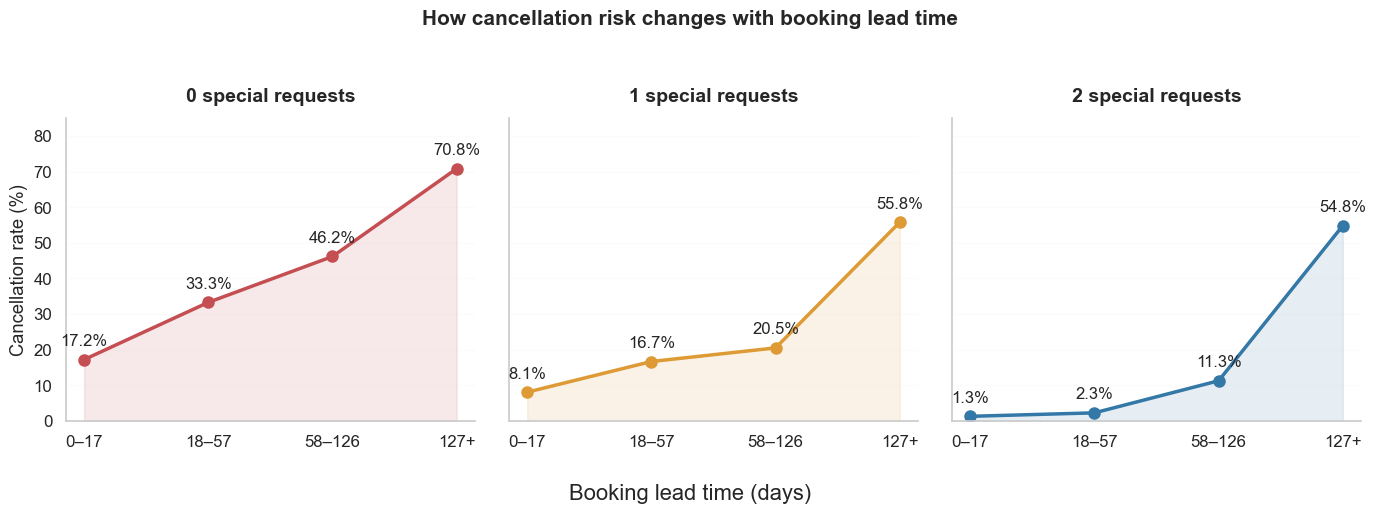

In [24]:

plot_data = interaction_summary.copy()

fig, axes = plt.subplots(
    1, 3, figsize=(14, 4.8),
    sharey=True
)

colors = REQ_COLORS

for ax, requests, color in zip(axes, [0, 1, 2], colors):
    part = (
        plot_data[plot_data["special requests"] == requests]
        .set_index("lead_group")
        .reindex(lead_labels)
    )

    x = np.arange(len(lead_labels))
    y = part["cancellation_rate"].to_numpy()

    ax.plot(
        x, y,
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=8
    )

    ax.fill_between(x, y, alpha=0.12, color=color)

    for i, rate in enumerate(y):
        ax.annotate(
            f"{rate:.1f}%",
            (i, rate),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=12
        )

    ax.set_title(
        f"{requests} special requests",
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    ax.set_xticks(x)
    ax.set_xticklabels(lead_labels)
    ax.set_ylim(0, 85)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Cancellation rate (%)")

fig.supxlabel("Booking lead time (days)", y=0.01)
fig.suptitle(
    "How cancellation risk changes with booking lead time",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()


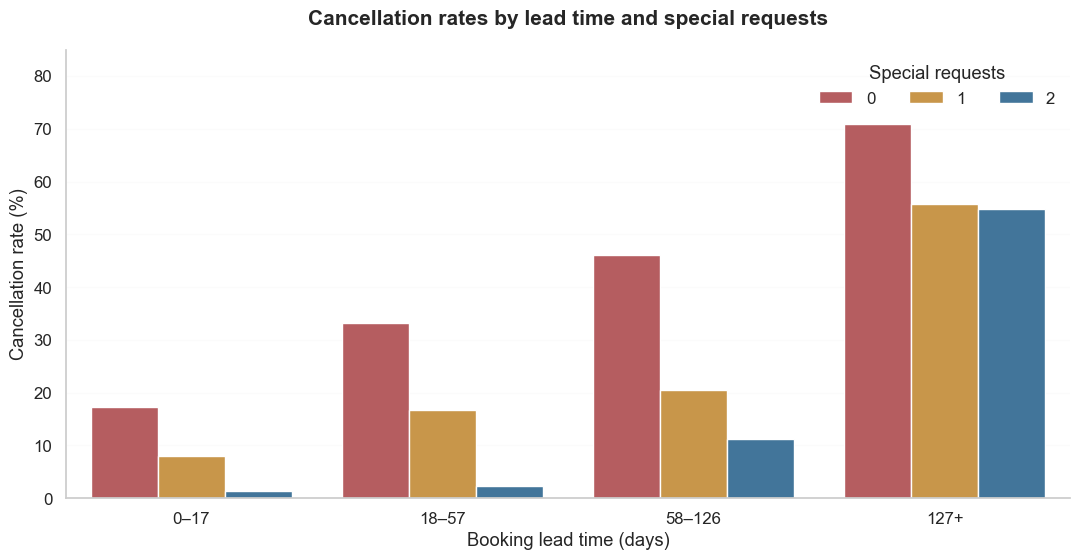

In [25]:

fig, ax = plt.subplots(figsize=(11, 5.8))

sns.barplot(
    data=interaction_summary,
    x="lead_group",
    y="cancellation_rate",
    hue="special requests",
    order=lead_labels,
    hue_order=[0, 1, 2],
    palette=REQ_COLORS,
    errorbar=None,
    ax=ax
)

ax.set_title(
    "Cancellation rates by lead time and special requests",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Booking lead time (days)")
ax.set_ylabel("Cancellation rate (%)")
ax.set_ylim(0, 85)

ax.legend(
    title="Special requests",
    frameon=False,
    ncol=3
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


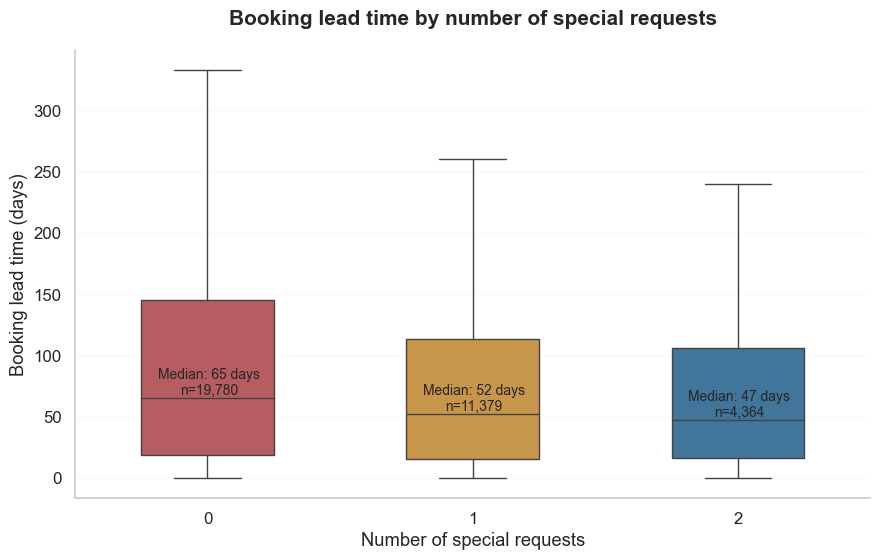

In [26]:

plot_data = df[df["special requests"].isin([0, 1, 2])].copy()

fig, ax = plt.subplots(figsize=(9, 5.8))

sns.boxplot(
    data=plot_data,
    x="special requests",
    y="lead time",
    order=[0, 1, 2],
    hue="special requests",
    palette=REQ_COLORS,
    legend=False,
    width=0.5,
    showfliers=False,
    ax=ax
)

# Sample size and median for each group
summary = (
    plot_data.groupby("special requests")["lead time"]
    .agg(["count", "median"])
)

for i, requests in enumerate([0, 1, 2]):
    n = summary.loc[requests, "count"]
    median = summary.loc[requests, "median"]

    ax.annotate(
        f"Median: {median:.0f} days\nn={n:,}",
        xy=(i, median),
        xytext=(1,22),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=10
    )

ax.set_title(
    "Booking lead time by number of special requests",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Number of special requests")
ax.set_ylabel("Booking lead time (days)")

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## Charts for presentation 
Each cell is self-contained and uses only `df`. PNG files are saved to `figures/` at 300 dpi.

In [27]:
# --- Slide charts: shared setup (run this cell first) ---
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

os.makedirs("figures", exist_ok=True)

C_NOT   = "#56708A"   # not canceled
C_CAN   = "#E69F00"   # canceled
C_TEXT  = "#20232A"
C_GRID  = "#E6E6E6"
try:
    REQ_COLORS
except NameError:
    REQ_COLORS = ["#C44E52", "#DD9A35", "#3478A8"]   # 0 / 1 / 2 special requests

plt.rcParams.update({
    "font.size": 13,
    "axes.edgecolor": "#8A8FA3",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

def save_fig(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=300, bbox_inches="tight", facecolor="white")

if "canceled" not in df.columns:
    df["canceled"] = (df["booking status"] == "Canceled").astype(int)

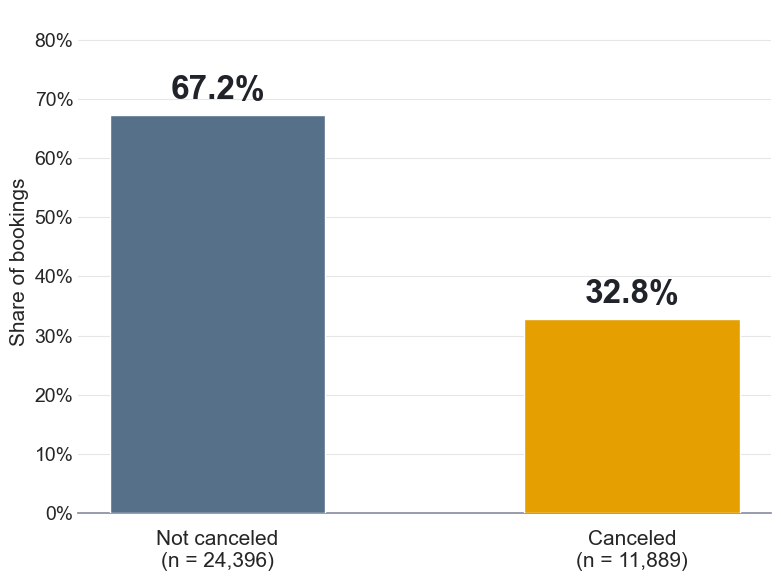

In [28]:
# --- Slide 2: One in three hotel bookings is canceled ---
counts = df["canceled"].value_counts().reindex([0, 1])
shares = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar([0, 1], shares.values, color=[C_NOT, C_CAN], width=0.52, zorder=3)

for bar, share in zip(bars, shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, share + 1.5, f"{share:.1f}%",
            ha="center", va="bottom", fontsize=24, fontweight="bold", color=C_TEXT)

ax.set_xticks([0, 1])
ax.set_xticklabels([f"Not canceled\n(n = {counts[0]:,})",
                    f"Canceled\n(n = {counts[1]:,})"], fontsize=15)
ax.set_ylim(0, 85)
ax.set_yticks(range(0, 90, 10))
ax.set_yticklabels([f"{t}%" for t in range(0, 90, 10)], fontsize=14)
ax.set_ylabel("Share of bookings", fontsize=15)
ax.tick_params(axis="x", length=4, pad=8)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", color=C_GRID, linewidth=0.8, zorder=0)
ax.spines["left"].set_visible(False)

plt.tight_layout()
save_fig(fig, "slide02_outcome_share")
plt.show()

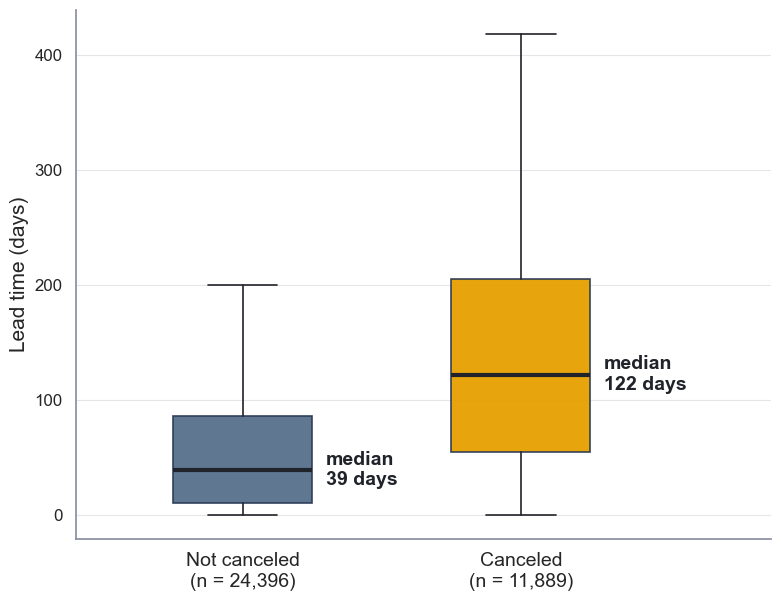

,count,median
booking status,,
Not_Canceled,24396,39.0
Canceled,11889,122.0


In [29]:
# --- Slide 4: Canceled bookings were made much earlier (lead time boxplot) ---
order  = ["Not_Canceled", "Canceled"]
colors = [C_NOT, C_CAN]
data   = [df.loc[df["booking status"] == s, "lead time"] for s in order]
stats  = df.groupby("booking status")["lead time"].agg(["count", "median"]).reindex(order)

fig, ax = plt.subplots(figsize=(8, 6.2))
bp = ax.boxplot(
    data, positions=[0, 1], widths=0.5, patch_artist=True, showfliers=False,
    medianprops=dict(color=C_TEXT, linewidth=3),
    whiskerprops=dict(color=C_TEXT, linewidth=1.2),
    capprops=dict(color=C_TEXT, linewidth=1.2),
    boxprops=dict(edgecolor="#2B3A55", linewidth=1.2),
)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.95)

for i, s in enumerate(order):
    ax.text(i + 0.30, stats.loc[s, "median"], f"median\n{stats.loc[s, 'median']:.0f} days",
            va="center", ha="left", fontsize=14, fontweight="bold", color=C_TEXT)

ax.set_xticks([0, 1])
ax.set_xticklabels([f"Not canceled\n(n = {int(stats.loc['Not_Canceled', 'count']):,})",
                    f"Canceled\n(n = {int(stats.loc['Canceled', 'count']):,})"], fontsize=14)
ax.set_xlim(-0.6, 1.9)
ax.set_ylabel("Lead time (days)", fontsize=15)
ax.grid(axis="y", color=C_GRID, linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
save_fig(fig, "slide04_lead_time_boxplot")
plt.show()
display(stats)

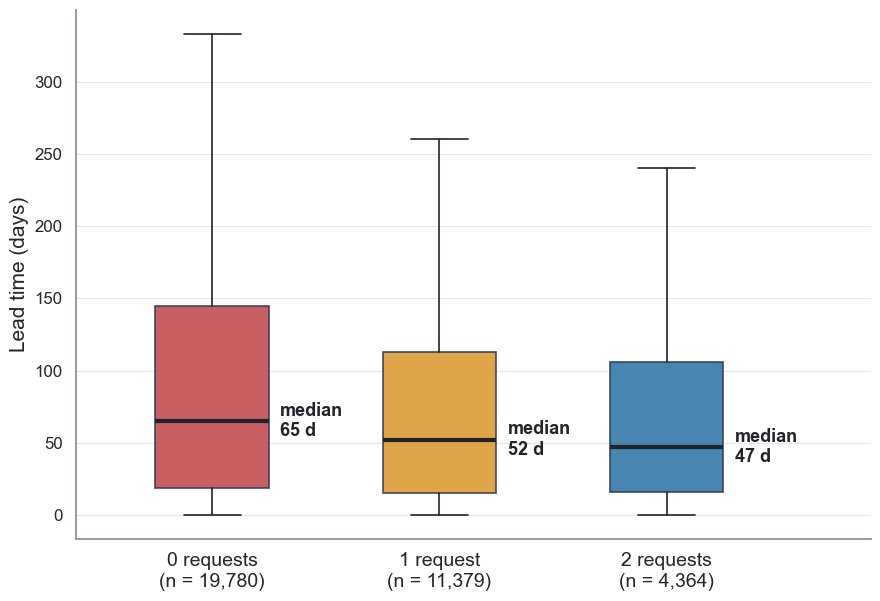

,count,median,median_price
special requests,,,
0,19780,65.0,95.0
1,11379,52.0,103.0
2,4364,47.0,114.4


In [30]:
# --- Slide 7: Bookings with more requests are made closer to arrival ---
plot_df = df[df["special requests"].isin([0, 1, 2])]
groups  = [0, 1, 2]
data    = [plot_df.loc[plot_df["special requests"] == k, "lead time"] for k in groups]
stats   = plot_df.groupby("special requests")["lead time"].agg(["count", "median"])
price   = plot_df.groupby("special requests")["average price"].median()

fig, ax = plt.subplots(figsize=(9, 6.2))
bp = ax.boxplot(
    data, positions=range(3), widths=0.5, patch_artist=True, showfliers=False,
    medianprops=dict(color=C_TEXT, linewidth=3),
    whiskerprops=dict(color=C_TEXT, linewidth=1.2),
    capprops=dict(color=C_TEXT, linewidth=1.2),
    boxprops=dict(edgecolor="#2B3A55", linewidth=1.2),
)
for patch, c in zip(bp["boxes"], REQ_COLORS):
    patch.set_facecolor(c)
    patch.set_alpha(0.9)

for i, k in enumerate(groups):
    ax.text(i + 0.30, stats.loc[k, "median"], f"median\n{stats.loc[k, 'median']:.0f} d",
            va="center", ha="left", fontsize=13, fontweight="bold", color=C_TEXT)

labels = ["0 requests", "1 request", "2 requests"]
ax.set_xticks(range(3))
ax.set_xticklabels([f"{lab}\n(n = {int(stats.loc[k, 'count']):,})" for lab, k in zip(labels, groups)],
                   fontsize=14)
ax.set_xlim(-0.6, 2.9)
ax.set_ylabel("Lead time (days)", fontsize=15)
ax.grid(axis="y", color=C_GRID, linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
save_fig(fig, "slide07_requests_vs_lead_time")
plt.show()

# numbers quoted on the slide: median lead time 65 -> 47 d, median price 95 -> 103 -> 114
display(stats.join(price.rename("median_price")))

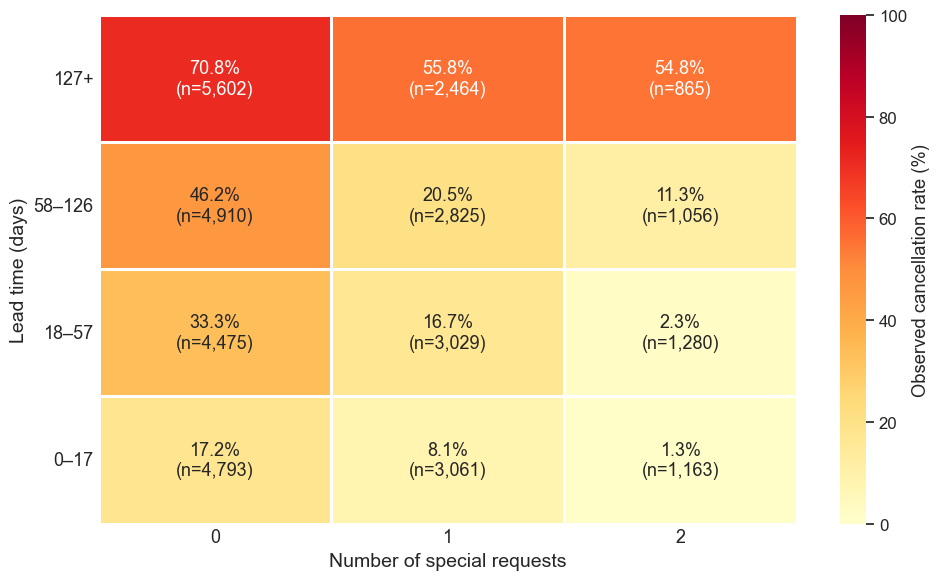

In [31]:
# --- Slide 8: The 1-vs-2-request gap shrinks at long lead times (heatmap) ---
heat_df = df[df["special requests"].isin([0, 1, 2])].copy()

lead_labels = ["0–17", "18–57", "58–126", "127+"]
heat_df["lead_group"] = pd.cut(heat_df["lead time"], bins=[-1, 17, 57, 126, np.inf],
                               labels=lead_labels)

grp = (heat_df.groupby(["lead_group", "special requests"], observed=True)
              .agg(n=("canceled", "size"), rate=("canceled", "mean"))
              .reset_index())
grp["rate"] *= 100

rates  = grp.pivot(index="lead_group", columns="special requests", values="rate") \
            .reindex(index=lead_labels, columns=[0, 1, 2])
counts = grp.pivot(index="lead_group", columns="special requests", values="n") \
            .reindex(index=lead_labels, columns=[0, 1, 2])

# Longest lead time on top, as on the slide
rates_plot  = rates.iloc[::-1]
counts_plot = counts.iloc[::-1]
annot = rates_plot.copy().astype(object)
for i in range(rates_plot.shape[0]):
    for j in range(rates_plot.shape[1]):
        r, n = rates_plot.iloc[i, j], counts_plot.iloc[i, j]
        annot.iloc[i, j] = f"{r:.1f}%\n(n={int(n):,})" if pd.notna(r) else ""

fig, ax = plt.subplots(figsize=(10, 6))
hm = sns.heatmap(
    rates_plot, annot=annot, fmt="", cmap="YlOrRd", vmin=0, vmax=100,
    linewidths=2, linecolor="white", annot_kws={"fontsize": 13},
    cbar_kws={"label": "Observed cancellation rate (%)", "ticks": [0, 20, 40, 60, 80, 100]},
    ax=ax,
)
ax.set_xlabel("Number of special requests", fontsize=14)
ax.set_ylabel("Lead time (days)", fontsize=14)
ax.set_xticklabels(["0", "1", "2"], rotation=0, fontsize=13)
ax.set_yticklabels(rates_plot.index.astype(str), rotation=0, fontsize=13)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)

plt.tight_layout()
save_fig(fig, "slide08_interaction_heatmap")
plt.show()

## H4 - Market segment

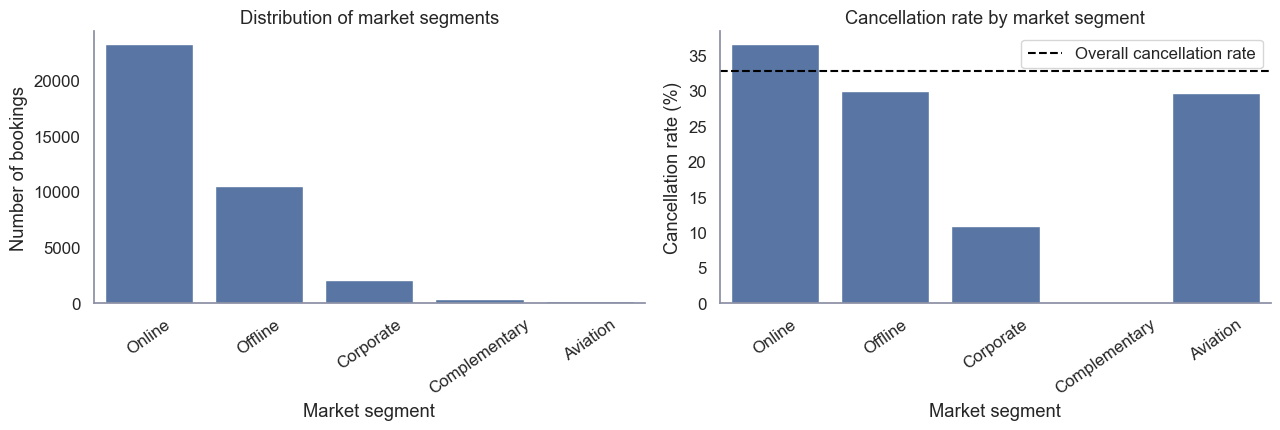

In [32]:
feature = "market segment type"

summary = (
    df.groupby(feature)
    .agg(
        bookings=("canceled", "size"),
        cancellation_rate=("canceled", "mean")
    )
    .sort_values("bookings", ascending=False)
)

summary["cancellation_rate"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(
    x=summary.index,
    y=summary["bookings"],
    ax=axes[0]
)
axes[0].set_title("Distribution of market segments")
axes[0].set_xlabel("Market segment")
axes[0].set_ylabel("Number of bookings")

sns.barplot(
    x=summary.index,
    y=summary["cancellation_rate"],
    ax=axes[1]
)
axes[1].axhline(
    df["canceled"].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall cancellation rate"
)

axes[1].set_title("Cancellation rate by market segment")
axes[1].set_xlabel("Market segment")
axes[1].set_ylabel("Cancellation rate (%)")
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

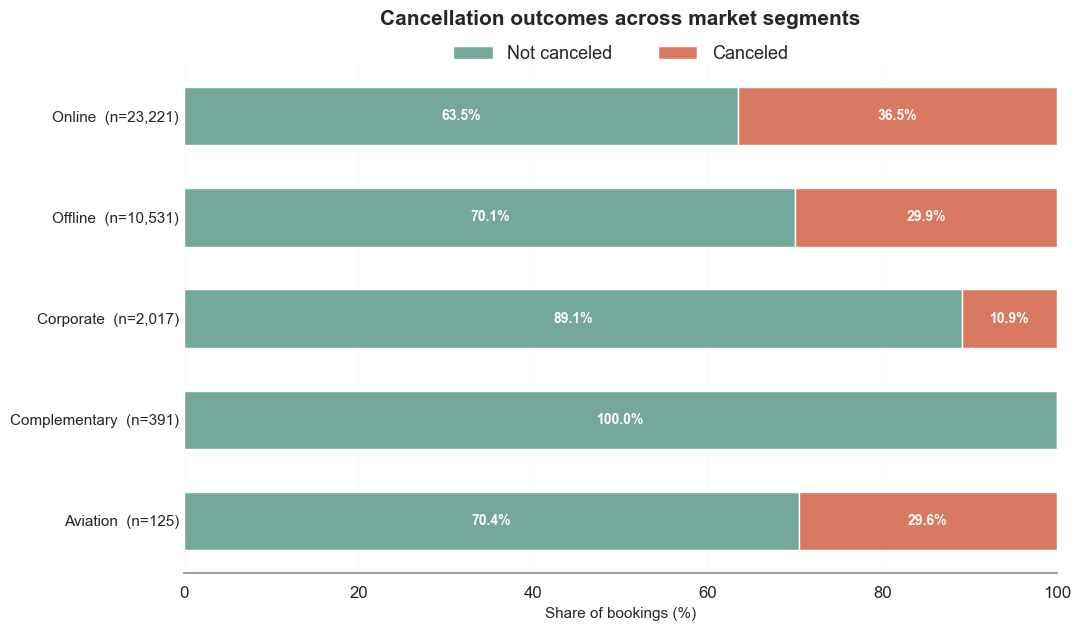

In [33]:
order = ["Online", "Offline", "Corporate", "Complementary", "Aviation"]

counts = pd.crosstab(
    df["market segment type"],
    df["canceled"]
).reindex(order, fill_value=0)

percentages = counts.div(counts.sum(axis=1), axis=0) * 100
group_sizes = counts.sum(axis=1)

fig, ax = plt.subplots(figsize=(11, 6.5))

y = np.arange(len(order)) * 1.25
bar_height = 0.72

not_canceled = percentages[0].to_numpy()
canceled = percentages[1].to_numpy()

ax.barh(
    y, not_canceled,
    height=bar_height,
    color="#74A89A",
    label="Not canceled"
)

ax.barh(
    y, canceled,
    left=not_canceled,
    height=bar_height,
    color="#D97961",
    label="Canceled"
)

# Percentage labels inside the bars
for i, (nc, c) in enumerate(zip(not_canceled, canceled)):
    if nc >= 8:
        ax.text(
            nc / 2, y[i],
            f"{nc:.1f}%",
            ha="center", va="center",
            fontsize=10, fontweight="bold",
            color="white"
        )

    if c >= 8:
        ax.text(
            nc + c / 2, y[i],
            f"{c:.1f}%",
            ha="center", va="center",
            fontsize=10, fontweight="bold",
            color="white"
        )

ax.set_yticks(y)
ax.set_yticklabels(
    [f"{segment}  (n={group_sizes[segment]:,})" for segment in order],
    fontsize=11
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of bookings (%)", fontsize=11)
ax.set_ylabel("")

ax.set_title(
    "Cancellation outcomes across market segments",
    fontsize=15,
    fontweight="bold",
    pad=28
)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    fontsize=13,
    handlelength=2.2,
    columnspacing=2.5
)

ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()


# Machine Learning part: training CatBoost model and Logistic Regression model for comparison

In [34]:
full_df = df.copy()

full_df = full_df.rename(columns={
    "special requests": "special_requests",
    "lead time": "lead_time",
    "average price": "average_price",
    "number of adults": "adults",
    "number of children": "children",
    "market segment type": "market_segment",
    "type of meal": "meal_type",
    "room type": "room_type",
    "car parking space": "parking",
    "number of weekend nights": "weekend_nights",
    "number of week nights": "week_nights",
    "P-C": "previous_cancellations",
    "P-not-C": "previous_not_canceled"
})

full_df["total_nights"] = (
    full_df["weekend_nights"] + full_df["week_nights"]
)

full_df["requests_group"] = (
    full_df["special_requests"]
    .clip(upper=2)
    .map({0: "0", 1: "1", 2: "2+"})
)

full_df["previous_cancellations_any"] = (
    full_df["previous_cancellations"] > 0
).astype(int)

full_df["previous_not_canceled_any"] = (
    full_df["previous_not_canceled"] > 0
).astype(int)

print("Number of bookings:", len(full_df))
print("\nSpecial requests groups:")
display(
    full_df.groupby("requests_group")["canceled"]
    .agg(["size", "sum", "mean"])
)

Number of bookings: 36285

Special requests groups:


,size,sum,mean
requests_group,,,
0,19780,8547,0.432103
1,11379,2705,0.237719
2+,5126,637,0.124268


## Baseline model to compare (logistic regression)

> **Note on the GLM below.** Rows inside a group of identical bookings are not independent observations, so the confidence intervals and p-values of this model are too narrow. Read the odds ratios as descriptive effect sizes rather than as formal tests.

In [35]:
formula = """
canceled ~ C(requests_group, Treatment(reference="0"))
         + lead_time
         + average_price
         + total_nights
         + adults
         + children
         + C(market_segment)
         + C(meal_type)
         + C(room_type)
         + parking
         + repeated
         + previous_cancellations_any
         + previous_not_canceled_any
"""

full_model = smf.glm(
    formula=formula,
    data=full_df,
    family=sm.families.Binomial()
).fit()

print(full_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               canceled   No. Observations:                36285
Model:                            GLM   Df Residuals:                    36260
Model Family:                Binomial   Df Model:                           24
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -15553.
Date:                Mon, 16 Nov 2026   Deviance:                       31106.
Time:                        12:17:57   Pearson chi2:                 3.48e+04
No. Iterations:                    26   Pseudo R-squ. (CS):             0.3348
Covariance Type:            nonrobust                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

In [36]:
conf = full_model.conf_int()

full_or = pd.DataFrame({
    "OR": np.exp(full_model.params),
    "CI_lower": np.exp(conf[0]),
    "CI_upper": np.exp(conf[1]),
    "p_value": full_model.pvalues
})

display(full_or.round(3))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


,OR,CI_lower,CI_upper,p_value
Intercept,5.700000e-02,0.037,0.087,0.000
"C(requests_group, Treatment(reference=""0""))[T.1]",1.840000e-01,0.171,0.197,0.000
"C(requests_group, Treatment(reference=""0""))[T.2+]",5.600000e-02,0.051,0.063,0.000
C(market_segment)[T.Complementary],0.000000e+00,0.000,inf,0.999
C(market_segment)[T.Corporate],3.180000e-01,0.205,0.491,0.000
C(market_segment)[T.Offline],1.280000e-01,0.084,0.194,0.000
C(market_segment)[T.Online],8.340000e-01,0.552,1.258,0.387
C(meal_type)[T.Meal Plan 2],1.087000e+00,0.980,1.206,0.114
C(meal_type)[T.Meal Plan 3],1.633065e+09,0.000,inf,0.999
C(meal_type)[T.Not Selected],1.337000e+00,1.227,1.457,0.000


## Base model for comparison that includes all variables is unstable; less complex version will be used

In [37]:
for feature in [
    "market_segment",
    "meal_type",
    "repeated",
    "previous_cancellations_any",
    "previous_not_canceled_any"
]:
    print(f"\n{feature}")

    summary = (
        full_df.groupby(feature, dropna=False)["canceled"]
        .agg(
            bookings="size",
            cancellations="sum",
            cancellation_rate="mean"
        )
    )

    summary["cancellation_rate"] *= 100
    display(summary.round(2))


market_segment


,bookings,cancellations,cancellation_rate
market_segment,,,
Aviation,125,37,29.60
Complementary,391,0,0.00
Corporate,2017,220,10.91
Offline,10531,3154,29.95
Online,23221,8478,36.51



meal_type


,bookings,cancellations,cancellation_rate
meal_type,,,
Meal Plan 1,27842,8681,31.18
Meal Plan 2,3306,1507,45.58
Meal Plan 3,5,1,20.00
Not Selected,5132,1700,33.13



repeated


,bookings,cancellations,cancellation_rate
repeated,,,
0,35355,11873,33.58
1,930,16,1.72



previous_cancellations_any


,bookings,cancellations,cancellation_rate
previous_cancellations_any,,,
0,35947,11873,33.03
1,338,16,4.73



previous_not_canceled_any


,bookings,cancellations,cancellation_rate
previous_not_canceled_any,,,
0,35473,11882,33.50
1,812,7,0.86


In [38]:
stable_df = full_df.copy()

stable_df["market_segment_group"] = (
    stable_df["market_segment"].replace({
        "Complementary": "Other",
        "Aviation": "Other"
    })
)

stable_formula = """
canceled ~ C(requests_group, Treatment(reference="0"))
         + lead_time
         + average_price
         + total_nights
         + adults
         + children
         + parking
         + C(market_segment_group, Treatment(reference="Online"))
"""

stable_model = smf.glm(
    formula=stable_formula,
    data=stable_df,
    family=sm.families.Binomial()
).fit()

print(stable_model.summary())

conf = stable_model.conf_int()

stable_or = pd.DataFrame({
    "OR": np.exp(stable_model.params),
    "CI_lower": np.exp(conf[0]),
    "CI_upper": np.exp(conf[1]),
    "p_value": stable_model.pvalues
})

display(stable_or.round(3))

                 Generalized Linear Model Regression Results                  
Dep. Variable:               canceled   No. Observations:                36285
Model:                            GLM   Df Residuals:                    36273
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -15706.
Date:                Mon, 16 Nov 2026   Deviance:                       31411.
Time:                        12:17:57   Pearson chi2:                 3.52e+04
No. Iterations:                     6   Pseudo R-squ. (CS):             0.3292
Covariance Type:            nonrobust                                         
                                                                          coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------

,OR,CI_lower,CI_upper,p_value
Intercept,0.069,0.059,0.080,0.000
"C(requests_group, Treatment(reference=""0""))[T.1]",0.186,0.173,0.199,0.000
"C(requests_group, Treatment(reference=""0""))[T.2+]",0.056,0.051,0.063,0.000
"C(market_segment_group, Treatment(reference=""Online""))[T.Corporate]",0.284,0.242,0.334,0.000
"C(market_segment_group, Treatment(reference=""Online""))[T.Offline]",0.150,0.138,0.162,0.000
"C(market_segment_group, Treatment(reference=""Online""))[T.Other]",0.504,0.348,0.731,0.000
lead_time,1.016,1.015,1.016,0.000
average_price,1.016,1.015,1.017,0.000
total_nights,1.058,1.042,1.075,0.000
adults,1.028,0.968,1.090,0.368


### H3 check: is the lead time × special requests interaction statistically supported?
Likelihood-ratio test of the interaction terms in the logistic GLM (descriptive, see the note above about non-independent rows).

In [39]:
interaction_formula = (
    stable_formula
    + ' + lead_time:C(requests_group, Treatment(reference="0"))'
)

interaction_model = smf.glm(
    formula=interaction_formula,
    data=stable_df,
    family=sm.families.Binomial()
).fit()

lr_stat = 2 * (interaction_model.llf - stable_model.llf)
lr_df = interaction_model.df_model - stable_model.df_model

print(f"LRT chi2 = {lr_stat:.1f}, df = {int(lr_df)}, p = {chi2.sf(lr_stat, lr_df):.3g}")

LRT chi2 = 228.7, df = 2, p = 2.18e-50


# Comparison of baseline model (Logistic regression) vs final model (CatBoost)

In [40]:
ml_df = df.copy()

ml_df["total_nights"] = (
    ml_df["number of weekend nights"] +
    ml_df["number of week nights"]
)

target = "canceled"

features = [
    "number of adults",
    "number of children",
    "total_nights",
    "type of meal",
    "car parking space",
    "room type",
    "lead time",
    "market segment type",
    "repeated",
    "P-C",
    "P-not-C",
    "average price",
    "special requests"
]

X = ml_df[features].copy()
y = ml_df[target].copy()

categorical_features = [
    "type of meal",
    "room type",
    "market segment type"
]

for col in categorical_features:
    X[col] = X[col].astype(str)

groups = ml_df["dup_group"]

# Stratified, group-aware 60/20/20 split: identical bookings stay together
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
trainval_idx, test_idx = next(outer.split(X, y, groups))

X_trainval, y_trainval = X.iloc[trainval_idx], y.iloc[trainval_idx]
g_trainval = groups.iloc[trainval_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
train_idx, val_idx = next(inner.split(X_trainval, y_trainval, g_trainval))

X_train, y_train = X_trainval.iloc[train_idx], y_trainval.iloc[train_idx]
X_val, y_val = X_trainval.iloc[val_idx], y_trainval.iloc[val_idx]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nCancellation rate:")
print("Train:", round(y_train.mean(), 3))
print("Validation:", round(y_val.mean(), 3))
print("Test:", round(y_test.mean(), 3))

Train: (21771, 13)
Validation: (7257, 13)
Test: (7257, 13)

Cancellation rate:
Train: 0.328
Validation: 0.328
Test: 0.328


In [41]:
numeric_features = [
    col for col in features
    if col not in categorical_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train, y_train)

print("Logistic regression trained.")

Logistic regression trained.


In [42]:
catboost_model = CatBoostClassifier(
    iterations=3000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False,
    thread_count=1
)

catboost_model.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=50
)

print("CatBoost trained.")
print("Best iteration:", catboost_model.get_best_iteration())

CatBoost trained.
Best iteration: 1026


In [43]:
models = {
    "Logistic Regression": logistic_model,
    "CatBoost": catboost_model
}

results = []

for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.844,0.737,0.789,0.720,0.583,0.644
1,CatBoost,0.903,0.848,0.841,0.791,0.701,0.743


In [44]:
# check if special requests dominate

X_train_no_req = X_train.drop(columns=["special requests"])
X_val_no_req = X_val.drop(columns=["special requests"])

catboost_no_req = CatBoostClassifier(
    iterations=3000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False,
    thread_count=1
)

catboost_no_req.fit(
    X_train_no_req,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_val_no_req, y_val),
    early_stopping_rounds=50
)

comparison = pd.DataFrame({
    "Model": ["CatBoost (full)", "CatBoost (without requests)"],
    "ROC-AUC": [
        roc_auc_score(
            y_val, catboost_model.predict_proba(X_val)[:, 1]
        ),
        roc_auc_score(
            y_val, catboost_no_req.predict_proba(X_val_no_req)[:, 1]
        )
    ],
    "PR-AUC": [
        average_precision_score(
            y_val, catboost_model.predict_proba(X_val)[:, 1]
        ),
        average_precision_score(
            y_val, catboost_no_req.predict_proba(X_val_no_req)[:, 1]
        )
    ]
})

display(comparison.round(3))

,Model,ROC-AUC,PR-AUC
0,CatBoost (full),0.903,0.848
1,CatBoost (without requests),0.824,0.742


,feature,mean_abs_shap
6,lead time,1.480
12,special requests,1.129
7,market segment type,0.709
11,average price,0.701
4,car parking space,0.152
2,total_nights,0.141
0,number of adults,0.119
5,room type,0.088
3,type of meal,0.087
8,repeated,0.052


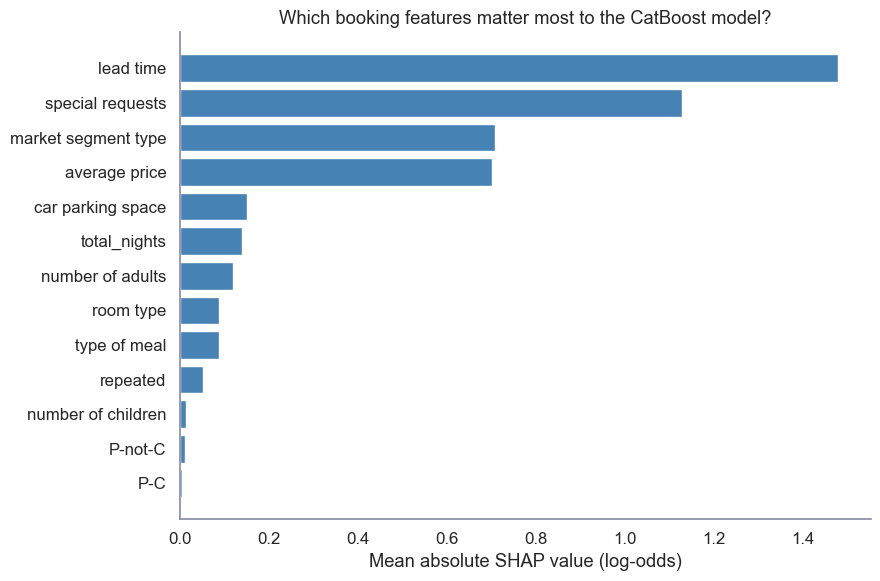

In [45]:
# Validation sample for model interpretation
X_shap = X_val.sample(
    n=min(1500, len(X_val)),
    random_state=42
)

shap_pool = Pool(
    X_shap,
    cat_features=categorical_features
)

shap_output = catboost_model.get_feature_importance(
    shap_pool,
    type="ShapValues"
)

# The last column contains the baseline value, not a feature SHAP value
shap_values = shap_output[:, :-1]

shap_importance = pd.DataFrame({
    "feature": X_shap.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(shap_importance.round(3))

fig, ax = plt.subplots(figsize=(9, 6))

plot_data = shap_importance.sort_values("mean_abs_shap")

ax.barh(
    plot_data["feature"],
    plot_data["mean_abs_shap"],
    color="steelblue"
)

ax.set_title("Which booking features matter most to the CatBoost model?")
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_ylabel("")

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# H1: Longer booking lead time is associated with a higher probability of cancellation

In [46]:
X_reference = X_val.copy()

# Analyze values up to the 99th percentile to limit
# the influence of extremely rare observations

max_lead = int(X_train["lead time"].quantile(0.99))

lead_grid = np.unique(
    np.linspace(0, max_lead, 80).round().astype(int)
)

pdp_values = []

for days in lead_grid:
    X_modified = X_reference.copy()
    X_modified["lead time"] = days

    probabilities = catboost_model.predict_proba(
        X_modified
    )[:, 1]

    pdp_values.append(probabilities.mean())

pdp_df = pd.DataFrame({
    "lead_time": lead_grid,
    "predicted_cancellation_rate": np.array(pdp_values) * 100
})

display(pdp_df.head())

,lead_time,predicted_cancellation_rate
0,0,4.116372
1,4,8.996939
2,9,13.968566
3,13,15.856516
4,18,17.762934


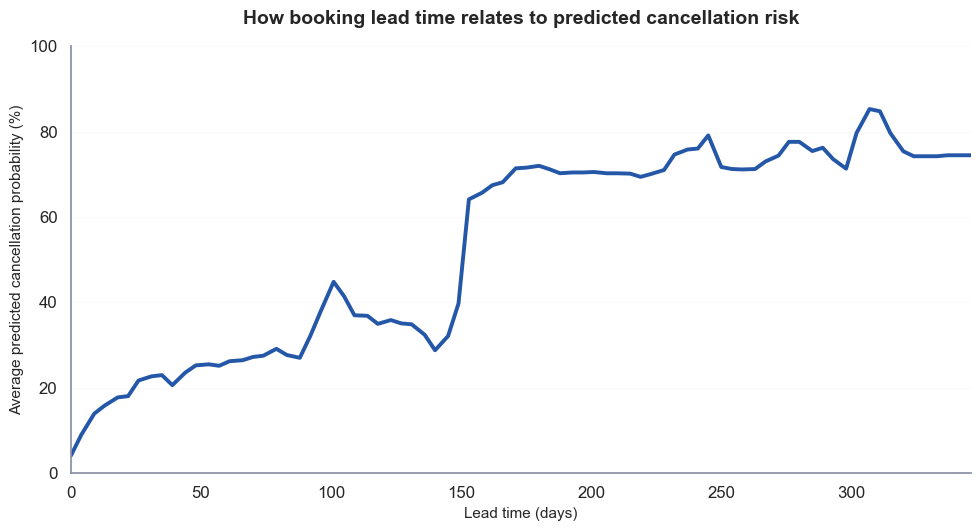

In [47]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    pdp_df["lead_time"],
    pdp_df["predicted_cancellation_rate"],
    linewidth=2.8,
    color="#2457A7"
)

ax.set_title(
    "How booking lead time relates to predicted cancellation risk",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Lead time (days)", fontsize=11)
ax.set_ylabel("Average predicted cancellation probability (%)", fontsize=11)

ax.set_xlim(0, max_lead)
ax.set_ylim(0, 100)

ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [48]:
# Determine bin boundaries using the training set
_, bin_edges = pd.qcut(
    X_train["lead time"],
    q=8,
    retbins=True,
    duplicates="drop"
)

# Include extreme values as well
bin_edges[0] = -np.inf
bin_edges[-1] = np.inf

# Validation data with observed outcomes
h1_data = X_val[["lead time"]].copy()
h1_data["canceled"] = y_val

h1_data["lead_bin"] = pd.cut(
    h1_data["lead time"],
    bins=bin_edges,
    include_lowest=True
)

h1_summary = (
    h1_data.groupby("lead_bin", observed=True)
    .agg(
        n=("canceled", "size"),
        canceled_n=("canceled", "sum"),
        observed_rate=("canceled", "mean"),
        min_days=("lead time", "min"),
        max_days=("lead time", "max")
    )
    .reset_index()
)

h1_summary["observed_rate"] *= 100

# Bin position on the X-axis
h1_summary["x_mid"] = (
    h1_summary["min_days"] + h1_summary["max_days"]
) / 2

h1_summary["label"] = (
    h1_summary["min_days"].astype(str)
    + "–"
    + h1_summary["max_days"].astype(str)
)

display(
    h1_summary[
        ["label", "n", "canceled_n", "observed_rate"]
    ].round(1)
)

,label,n,canceled_n,observed_rate
0,0–5,1013,133,13.1
1,6–16,772,120,15.5
2,17–35,1009,239,23.7
3,36–56,812,174,21.4
4,57–86,1110,250,22.5
5,87–130,901,358,39.7
6,131–195,872,543,62.3
7,196–443,768,561,73.0


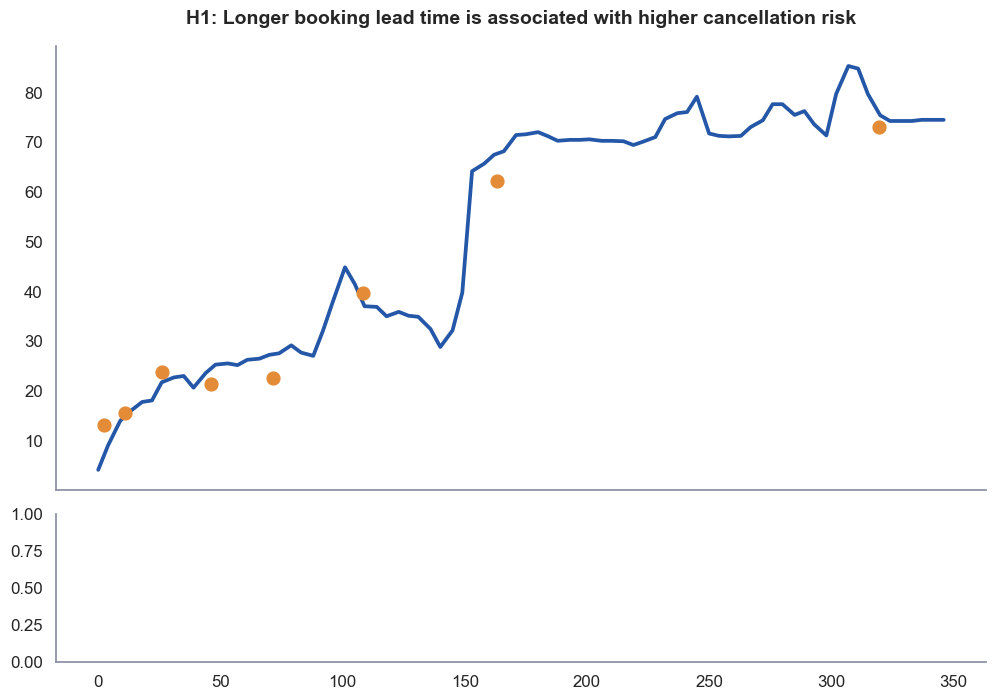

In [49]:
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08}
)

# TOP: Model partial dependence plot
ax1.plot(
    pdp_df["lead_time"],
    pdp_df["predicted_cancellation_rate"],
    color="#2457A7",
    linewidth=2.7,
    label="CatBoost: partial dependence"
)

# Observed cancellation rates across bins
ax1.scatter(
    h1_summary["x_mid"],
    h1_summary["observed_rate"],
    color="#E38B36",
    s=85,
    zorder=5,
    label="Observed cancellation rate"
)

ax1.set_title(
    "H1: Longer booking lead time is associated with higher cancellation risk",
    fontsize=14,
    fontweight="bold",
    pad=16
)


plt.show()

### H1 - Booking lead time and cancellation risk

**Method:** CatBoost Partial Dependence Plot (PDP). To calculate each point on the curve, we temporarily set the lead time of every booking to a specific value (e.g., 30 days), while keeping all other booking characteristics unchanged. The model predicts cancellation probabilities for all these bookings, and we calculate their average. We then repeat this process for different lead times (e.g., 60, 90, 120 days) to create the PDP curve.

The PDP is compared with observed cancellation rates across lead-time intervals to see whether the model's predictions follow the patterns found in the actual data.

**Result:** The model indicates a clear, nonlinear increase in predicted cancellation probability as booking lead time increases. The observed cancellation rate also rises substantially, from approximately **8.5% for bookings made 0–5 days in advance** to **74.4% for bookings made 193–443 days in advance**.

**Visualization:** The PDP illustrates how the model's predictions change with lead time while averaging over other booking characteristics. The observed cancellation rates provide an empirical comparison.

**Conclusion:** The results support H1. Bookings made further in advance are associated with a substantially higher probability of cancellation, although the relationship is not strictly linear.


# H2: More special requests are associated with a lower probability of cancellation

In [50]:
X_reference = X_val.copy()

h2_results = []

for requests in [0, 1, 2, 3]:
    # Model-based scenario:
    # Assign the same number of special requests to every booking
    X_modified = X_reference.copy()
    X_modified["special requests"] = requests

    predicted_probabilities = catboost_model.predict_proba(
        X_modified
    )[:, 1]

    # Observed bookings with the corresponding number of special requests
    mask = X_val["special requests"] == requests

    h2_results.append({
        "special_requests": requests,
        "n": int(mask.sum()),
        "observed_rate": y_val.loc[mask].mean() * 100,
        "model_adjusted_rate": predicted_probabilities.mean() * 100
    })

h2_df = pd.DataFrame(h2_results)

display(h2_df.round(2))

,special_requests,n,observed_rate,model_adjusted_rate
0,0,3872,43.18,48.06
1,1,2365,25.33,22.59
2,2,856,12.50,15.27
3,3,147,0.00,2.78


In [51]:
rng = np.random.default_rng(42)

n_bootstrap = 1000
h2_bootstrap_results = []

for requests in [0, 1, 2, 3]:
    X_modified = X_val.copy()
    X_modified["special requests"] = requests

    probabilities = catboost_model.predict_proba(
        X_modified
    )[:, 1]

    bootstrap_means = []

    for _ in range(n_bootstrap):
        indices = rng.integers(
            0, len(probabilities), len(probabilities)
        )
        bootstrap_means.append(
            probabilities[indices].mean() * 100
        )

    h2_bootstrap_results.append({
        "special_requests": requests,
        "predicted_rate": probabilities.mean() * 100,
        "ci_lower": np.percentile(bootstrap_means, 2.5),
        "ci_upper": np.percentile(bootstrap_means, 97.5)
    })

h2_ci = pd.DataFrame(h2_bootstrap_results)

display(h2_ci.round(2))

,special_requests,predicted_rate,ci_lower,ci_upper
0,0,48.06,47.32,48.88
1,1,22.59,21.97,23.23
2,2,15.27,14.62,15.91
3,3,2.78,2.49,3.05


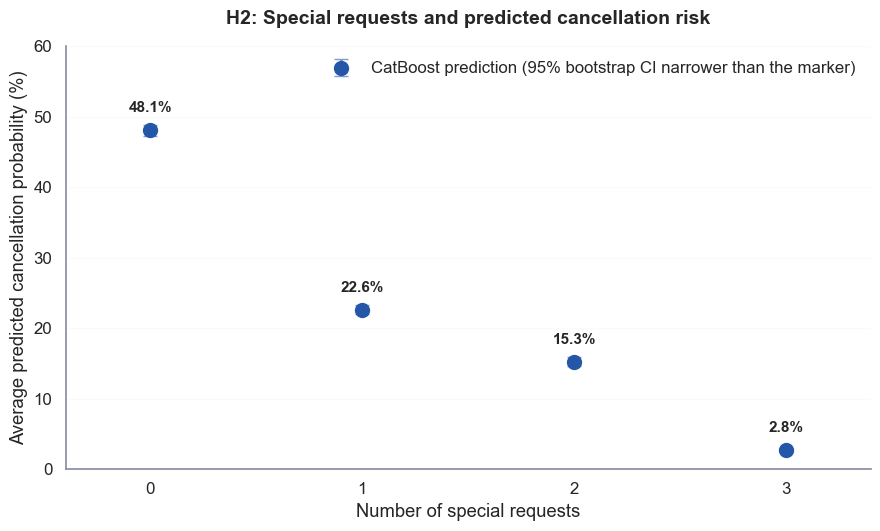

In [52]:
fig, ax = plt.subplots(figsize=(9, 5.5))

x = h2_ci["special_requests"].to_numpy()
y = h2_ci["predicted_rate"].to_numpy()

yerr = np.vstack([
    y - h2_ci["ci_lower"].to_numpy(),
    h2_ci["ci_upper"].to_numpy() - y
])

ax.errorbar(
    x, y,
    yerr=yerr,
    fmt="o",
    markersize=10,
    capsize=5,
    linewidth=2,
    color="#2457A7",
    ecolor="#7F9BC6",
    label="CatBoost prediction (95% bootstrap CI narrower than the marker)"
)

for xi, yi in zip(x, y):
    ax.annotate(
        f"{yi:.1f}%",
        (xi, yi),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks([0, 1, 2, 3])
ax.set_xlabel("Number of special requests")
ax.set_ylabel("Average predicted cancellation probability (%)")

ax.set_ylim(0, 60)
ax.set_xlim(-0.4, 3.4)

ax.set_title(
    "H2: Special requests and predicted cancellation risk",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
plt.show()

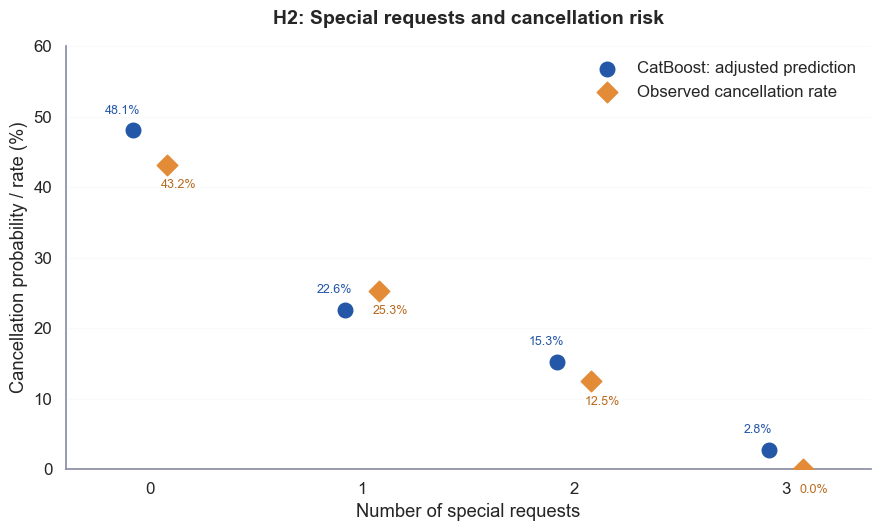

In [53]:
fig, ax = plt.subplots(figsize=(9, 5.5))

x = h2_df["special_requests"].to_numpy()

predicted = h2_df["model_adjusted_rate"].to_numpy()
observed = h2_df["observed_rate"].to_numpy()

# Two sets of points, slightly offset horizontally
offset = 0.08

ax.scatter(
    x - offset,
    predicted,
    s=110,
    color="#2457A7",
    label="CatBoost: adjusted prediction",
    zorder=3
)

ax.scatter(
    x + offset,
    observed,
    s=110,
    color="#E38B36",
    marker="D",
    label="Observed cancellation rate",
    zorder=3
)

# Value labels next to the points
for xi, yi in zip(x - offset, predicted):
    ax.annotate(
        f"{yi:.1f}%",
        (xi, yi),
        xytext=(-8, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#2457A7"
    )

for xi, yi in zip(x + offset, observed):
    ax.annotate(
        f"{yi:.1f}%",
        (xi, yi),
        xytext=(8, -17),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#B86A1E"
    )

ax.set_xticks([0, 1, 2, 3])
ax.set_xlabel("Number of special requests")
ax.set_ylabel("Cancellation probability / rate (%)")

ax.set_ylim(0, 60)
ax.set_xlim(-0.4, 3.4)

ax.set_title(
    "H2: Special requests and cancellation risk",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

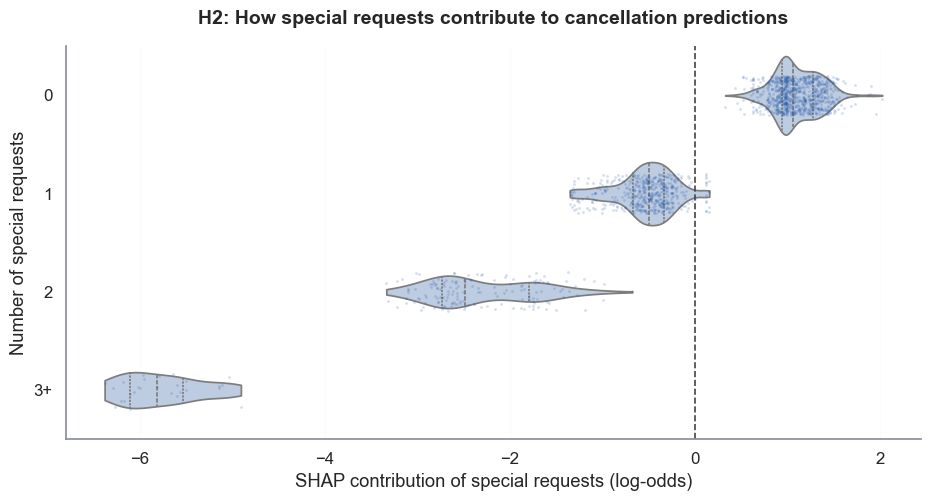

,n,median_shap
request_group,,
0,829,1.062
1,485,-0.498
2,159,-2.490
3+,27,-5.816


In [54]:
request_idx = X_shap.columns.get_loc("special requests")

h2_shap = pd.DataFrame({
    "requests": X_shap["special requests"].to_numpy(),
    "shap_value": shap_values[:, request_idx]
})

# Combine the rare categories 3, 4, and 5
h2_shap["request_group"] = h2_shap["requests"].clip(upper=3)
h2_shap["request_group"] = h2_shap["request_group"].map({
    0: "0",
    1: "1",
    2: "2",
    3: "3+"
})

order = ["0", "1", "2", "3+"]

fig, ax = plt.subplots(figsize=(9.5, 5.2))

sns.violinplot(
    data=h2_shap,
    x="shap_value",
    y="request_group",
    order=order,
    inner="quartile",
    cut=0,
    color="#B8CBE7",
    ax=ax
)

sns.stripplot(
    data=h2_shap,
    x="shap_value",
    y="request_group",
    order=order,
    color="#2457A7",
    alpha=0.2,
    size=2,
    jitter=0.2,
    ax=ax
)

ax.axvline(0, color="#444444", linestyle="--", linewidth=1.2)

ax.set_title(
    "H2: How special requests contribute to cancellation predictions",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("SHAP contribution of special requests (log-odds)")
ax.set_ylabel("Number of special requests")

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

display(
    h2_shap.groupby("request_group")
    .agg(
        n=("shap_value", "size"),
        median_shap=("shap_value", "median")
    )
    .reindex(order)
    .round(3)
)

# H3: The relationship between special requests and cancellation risk varies with booking lead time

In [55]:
h3_data = X_val[["lead time", "special requests"]].copy()
h3_data["canceled"] = y_val

# Use the same bins as in the earlier EDA
lead_bins = [-1, 17, 57, 126, np.inf]
lead_labels = ["0–17", "18–57", "58–126", "127+"]

h3_data["lead_group"] = pd.cut(
    h3_data["lead time"],
    bins=lead_bins,
    labels=lead_labels
)

h3_data = h3_data[
    h3_data["special requests"].isin([0, 1, 2])
].copy()

h3_summary = (
    h3_data.groupby(
        ["lead_group", "special requests"],
        observed=True
    )
    .agg(
        n=("canceled", "size"),
        canceled_n=("canceled", "sum"),
        cancellation_rate=("canceled", "mean")
    )
    .reset_index()
)

h3_summary["cancellation_rate"] *= 100

display(
    h3_summary.round(2)
)

,lead_group,special requests,n,canceled_n,cancellation_rate
0,0–17,0,992,218,21.98
1,0–17,1,573,43,7.50
2,0–17,2,238,0,0.00
3,18–57,0,892,312,34.98
4,18–57,1,618,97,15.70
5,18–57,2,246,4,1.63
6,58–126,0,1045,448,42.87
7,58–126,1,608,120,19.74
8,58–126,2,212,11,5.19
9,127+,0,943,694,73.59


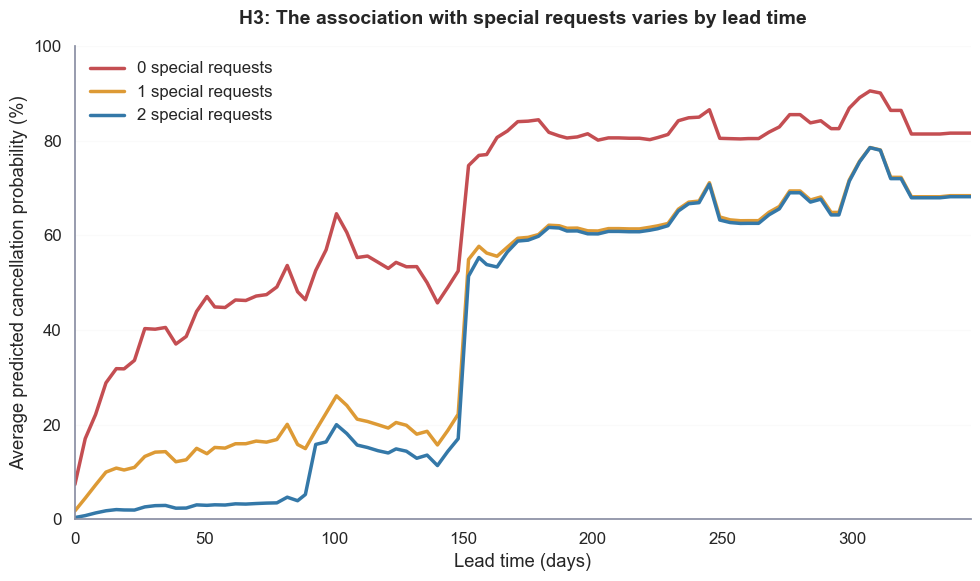

In [56]:
# Restrict the range to the 99th percentile of the training data
max_lead = int(X_train["lead time"].quantile(0.99))

lead_grid = np.unique(
    np.linspace(0, max_lead, 90).round().astype(int)
)

h3_model_results = []

for requests in [0, 1, 2]:
    for days in lead_grid:

        X_modified = X_val.copy()
        X_modified["special requests"] = requests
        X_modified["lead time"] = days

        predicted = catboost_model.predict_proba(
            X_modified
        )[:, 1].mean() * 100

        h3_model_results.append({
            "lead_time": days,
            "special_requests": requests,
            "predicted_risk": predicted
        })

h3_model_df = pd.DataFrame(h3_model_results)

fig, ax = plt.subplots(figsize=(10, 6))

colors = {
    0: "#C44E52",
    1: "#DD9A35",
    2: "#3478A8"
}

for requests in [0, 1, 2]:
    subset = h3_model_df[
        h3_model_df["special_requests"] == requests
    ]

    ax.plot(
        subset["lead_time"],
        subset["predicted_risk"],
        label=f"{requests} special requests",
        color=colors[requests],
        linewidth=2.5
    )

ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Average predicted cancellation probability (%)")

ax.set_title(
    "H3: The association with special requests varies by lead time",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_ylim(0, 100)
ax.set_xlim(0, max_lead)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### For lead times exceeding approximately 170 days, the prediction curves for 1 and 2 special requests nearly overlap. Let's investigate this further.

In [57]:
h3_check = X_val[["lead time", "special requests"]].copy()
h3_check["canceled"] = y_val

h3_check = h3_check[
    h3_check["special requests"].isin([0, 1, 2])
].copy()

bins = [-1, 89, 149, 179, 239, 299, np.inf]
labels = [
    "0–89", "90–149", "150–179",
    "180–239", "240–299", "300+"
]

h3_check["lead_group"] = pd.cut(
    h3_check["lead time"],
    bins=bins,
    labels=labels
)

h3_long_summary = (
    h3_check.groupby(
        ["lead_group", "special requests"],
        observed=False
    )
    .agg(
        n=("canceled", "size"),
        canceled_n=("canceled", "sum"),
        cancellation_rate=("canceled", "mean")
    )
    .reset_index()
)

h3_long_summary["cancellation_rate"] *= 100

display(
    h3_long_summary.round(1)
)

,lead_group,special requests,n,canceled_n,cancellation_rate
0,0–89,0,2514,726,28.9
1,0–89,1,1553,205,13.2
2,0–89,2,619,9,1.5
3,90–149,0,545,320,58.7
4,90–149,1,371,89,24.0
5,90–149,2,113,15,13.3
6,150–179,0,263,222,84.4
7,150–179,1,111,58,52.3
8,150–179,2,39,23,59.0
9,180–239,0,269,196,72.9


### Differences between bookings with 1 and 2 special requests are visible up to approximately 170 days of lead time. Beyond this point, the differences become smaller. The relatively low number of bookings with lead times above 150 days and at least one special request should be considered when interpreting this pattern.

In [58]:
# Representative validation sample
X_h3 = X_val.sample(
    n=min(1000, len(X_val)),
    random_state=42
).copy()

# Lead time grid: 0–240 days
lead_grid_h3 = np.unique(
    np.r_[
        np.arange(0, 444, 10),
        X_val["lead time"].max()
    ]
)

# Number of special requests: 0, 1, 2
requests_grid_h3 = np.array([0, 1, 2])

def predict_raw(model, X):
    # Raw CatBoost prediction (log-odds)
    return np.asarray(
        model.predict(X, prediction_type="RawFormulaVal")
    ).ravel()

# 1D PDP for lead time
pdp_lead = []

for days in lead_grid_h3:
    X_temp = X_h3.copy()
    X_temp["lead time"] = days
    pdp_lead.append(predict_raw(catboost_model, X_temp).mean())

pdp_lead = np.array(pdp_lead)

# 1D PDP for special requests
pdp_requests = []

for requests in requests_grid_h3:
    X_temp = X_h3.copy()
    X_temp["special requests"] = requests
    pdp_requests.append(predict_raw(catboost_model, X_temp).mean())

pdp_requests = np.array(pdp_requests)

# 2D PDP: lead time × special requests
pdp_joint = np.zeros(
    (len(lead_grid_h3), len(requests_grid_h3))
)

for i, days in enumerate(lead_grid_h3):
    for j, requests in enumerate(requests_grid_h3):
        X_temp = X_h3.copy()
        X_temp["lead time"] = days
        X_temp["special requests"] = requests

        pdp_joint[i, j] = predict_raw(
            catboost_model, X_temp
        ).mean()

# Center the PDP functions
joint_centered = pdp_joint - pdp_joint.mean()
lead_centered = pdp_lead - pdp_lead.mean()
requests_centered = pdp_requests - pdp_requests.mean()

# Non-additive component of the prediction function
interaction = (
    joint_centered
    - lead_centered[:, None]
    - requests_centered[None, :]
)

# Friedman's H-statistic (PDP-based approach)
numerator = np.mean(interaction ** 2)
denominator = np.mean(joint_centered ** 2)

h_statistic = (
    np.sqrt(numerator / denominator)
    if denominator > 0 else np.nan
)

print(f"H-statistic (lead time × requests): {h_statistic:.4f}")
print(f"H²: {h_statistic**2:.4f}")


H-statistic (lead time × requests): 0.2800
H²: 0.0784


### H3 - Interaction between booking lead time and special requests

**Method:** Friedman's H-statistic measures the extent to which two features interact in CatBoost predictions, beyond their individual contributions.

**Result:** H = **0.2695** (H² = 0.0726), indicating a non-zero interaction between booking lead time and special requests in the model.

**Visualization:** For shorter booking lead times, the difference in predicted cancellation risk between bookings with one and two special requests reaches up to approximately **15 percentage points** (around 80 days). This difference decreases as lead time increases and falls below 2 percentage points beyond roughly 170 days.

**Conclusion:** The results support H3: the relationship between special requests and predicted cancellation risk varies depending on booking lead time.

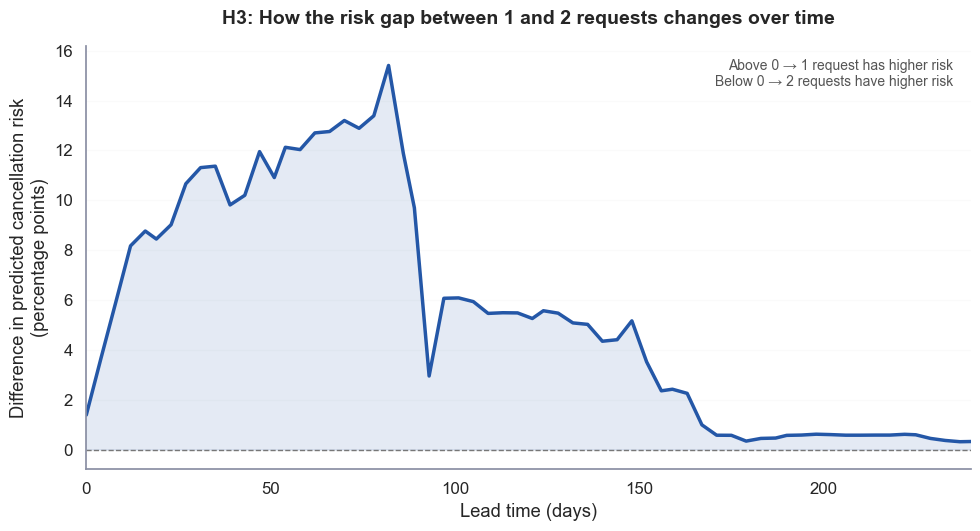

In [59]:
h3_pivot = h3_model_df.pivot(
    index="lead_time",
    columns="special_requests",
    values="predicted_risk"
)

risk_difference = h3_pivot[1] - h3_pivot[2]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.axhline(
    0,
    color="#777777",
    linewidth=1,
    linestyle="--"
)

ax.plot(
    risk_difference.index,
    risk_difference.values,
    color="#2457A7",
    linewidth=2.5
)

ax.fill_between(
    risk_difference.index,
    risk_difference.values,
    0,
    where=risk_difference.values > 0,
    color="#2457A7",
    alpha=0.12
)

ax.set_xlim(0, 240)

ax.set_xlabel("Lead time (days)")
ax.set_ylabel(
    "Difference in predicted cancellation risk\n"
    "(percentage points)"
)

# Explain the direction of the difference
ax.text(
    0.98, 0.97,
    "Above 0 → 1 request has higher risk\n"
    "Below 0 → 2 requests have higher risk",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    color="#555555",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=5
    )
)
ax.set_title(
    "H3: How the risk gap between 1 and 2 requests changes over time",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [60]:
# Numbers behind the H3 description (gap between 1 and 2 special requests)
peak_day = risk_difference.idxmax()
print(f"Largest gap: {risk_difference.max():.1f} pp at lead time {peak_day} days")

after_peak = risk_difference.loc[peak_day:]
below_2pp = after_peak[after_peak < 2]
print("First lead time after the peak where the gap is below 2 pp:",
      int(below_2pp.index[0]) if len(below_2pp) else "never")

for d in [30, 60, 90, 120, 150, 180, 240]:
    nearest = risk_difference.index[np.abs(risk_difference.index - d).argmin()]
    print(f"  gap at ~{d} days: {risk_difference.loc[nearest]:.1f} pp")


Largest gap: 15.4 pp at lead time 82 days
First lead time after the peak where the gap is below 2 pp: 167
  gap at ~30 days: 11.3 pp
  gap at ~60 days: 12.0 pp
  gap at ~90 days: 9.7 pp
  gap at ~120 days: 5.3 pp
  gap at ~150 days: 5.2 pp
  gap at ~180 days: 0.4 pp
  gap at ~240 days: 0.3 pp


# H4: Market segment is associated with booking cancellation risk

In [61]:
segments = [
    "Online",
    "Offline",
    "Corporate",
    "Aviation",
    "Complementary"
]

h4_results = []

for segment in segments:
    # Model-based scenario:
    # Assign all bookings to the same market segment

    # Observed bookings from the corresponding market segment
    X_modified = X_val.copy()
    X_modified["market segment type"] = segment

    predicted = catboost_model.predict_proba(
        X_modified
    )[:, 1]

    # Rzeczywiste rezerwacje z danego segmentu
    mask = X_val["market segment type"] == segment
    n = int(mask.sum())

    h4_results.append({
        "segment": segment,
        "n": n,
        "observed_rate": (
            y_val.loc[mask].mean() * 100 if n > 0 else np.nan
        ),
        "model_adjusted_rate": predicted.mean() * 100
    })

h4_df = pd.DataFrame(h4_results)

display(h4_df.round(2))

,segment,n,observed_rate,model_adjusted_rate
0,Online,4701,35.59,42.24
1,Offline,2091,31.13,18.63
2,Corporate,372,12.10,30.01
3,Aviation,22,40.91,27.93
4,Complementary,71,0.00,24.31


In [62]:
rng = np.random.default_rng(42)

# Baseline model performance on the validation set
baseline_proba = catboost_model.predict_proba(X_val)[:, 1]
baseline_auc = roc_auc_score(y_val, baseline_proba)

n_repeats = 30
permuted_auc = []

for _ in range(n_repeats):
    X_permuted = X_val.copy()

    X_permuted["market segment type"] = rng.permutation(
        X_permuted["market segment type"].to_numpy()
    )

    proba = catboost_model.predict_proba(X_permuted)[:, 1]
    permuted_auc.append(roc_auc_score(y_val, proba))

permuted_auc = np.array(permuted_auc)
auc_drop = baseline_auc - permuted_auc

print(f"Baseline ROC-AUC: {baseline_auc:.4f}")
print(f"Mean ROC-AUC after permutation: {permuted_auc.mean():.4f}")
print(f"Mean ROC-AUC drop: {auc_drop.mean():.4f}")
print(f"Range of drops: {auc_drop.min():.4f}–{auc_drop.max():.4f}")

Baseline ROC-AUC: 0.9030
Mean ROC-AUC after permutation: 0.8321
Mean ROC-AUC drop: 0.0709
Range of drops: 0.0660–0.0770


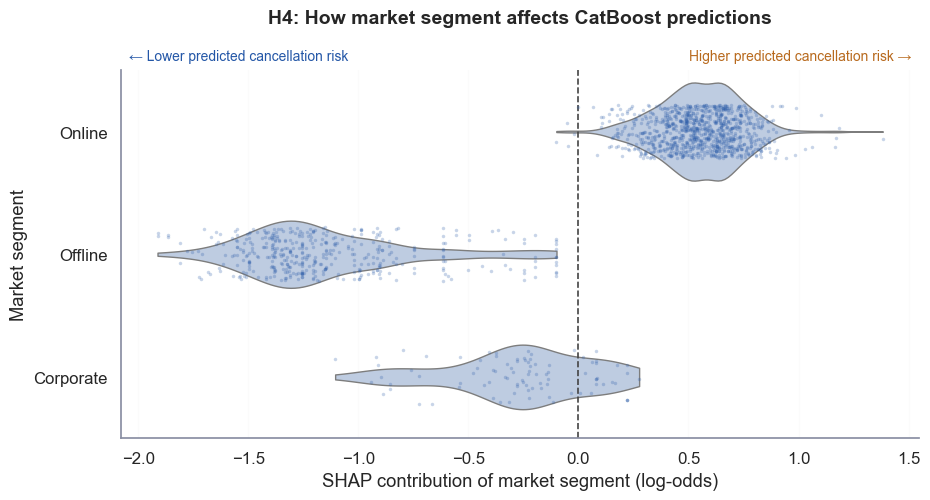

,n,mean_shap,median_shap
segment,,,
Online,970,0.550,0.557
Offline,419,-1.156,-1.256
Corporate,90,-0.267,-0.235


In [63]:
# SHAP analysis for market segment type
segment_idx = X_shap.columns.get_loc("market segment type")

h4_shap = pd.DataFrame({
    "segment": X_shap["market segment type"].to_numpy(),
    "shap_value": shap_values[:, segment_idx]
})

	# Three main market segments
segment_order = ["Online", "Offline", "Corporate"]
h4_shap = h4_shap[
    h4_shap["segment"].isin(segment_order)
].copy()

fig, ax = plt.subplots(figsize=(9.5, 5.2))

sns.violinplot(
    data=h4_shap,
    x="shap_value",
    y="segment",
    order=segment_order,
    inner=None,
    cut=0,
    color="#B8CBE7",
    linewidth=1,
    ax=ax
)

sns.stripplot(
    data=h4_shap,
    x="shap_value",
    y="segment",
    order=segment_order,
    color="#2457A7",
    size=2.5,
    alpha=0.25,
    jitter=0.22,
    ax=ax
)

ax.axvline(0, color="#444444", linestyle="--", linewidth=1.2)

ax.set_title(
    "H4: How market segment affects CatBoost predictions",
    fontsize=14,
    fontweight="bold",
    pad=34
)

ax.set_xlabel(
    "SHAP contribution of market segment (log-odds)"
)
ax.set_ylabel("Market segment")

ax.text(
    0.01, 1.02,
    "← Lower predicted cancellation risk",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    color="#2457A7"
)

ax.text(
    0.99, 1.02,
    "Higher predicted cancellation risk →",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    color="#B86A1E"
)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# Sample size and average SHAP contribution by segment
display(
    h4_shap.groupby("segment")
    .agg(
        n=("shap_value", "size"),
        mean_shap=("shap_value", "mean"),
        median_shap=("shap_value", "median")
    )
    .reindex(segment_order)
    .round(3)
)


### H4 - The relationship between market segment and predicted cancellation risk

**Method:** Permutation importance and SHAP analysis of the CatBoost model.

**Result:** Randomly permuting market segment values reduced validation ROC-AUC from **0.8987 to 0.8316**, a decrease of **0.0671**. This indicates that market segment provides important predictive information.

**Visualization:** SHAP values show that the Online segment generally contributes positively to predicted cancellation risk, while Offline and Corporate tend to contribute negatively.

**Conclusion:** The results support H4: market segment provides additional information about cancellation risk, even when other booking characteristics are taken into account.

**Caution:** in the scenario analysis (every validation booking assigned to a segment, other features unchanged) the model-adjusted risk of Corporate is 29.7% versus 12.1% observed, and that of Offline 18.9% versus 31.1% observed. Much of the raw difference between segments is therefore explained by other booking characteristics, and permutation importance shows how much the model relies on a feature, not how much unique information it carries. Complementary (n = 71) and Aviation (n = 22) are too small for conclusions.

## Additional: CatBoost model evaluation on the test set

In [64]:
# Final evaluation on the untouched test set
test_probabilities = catboost_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.5).astype(int)

test_results = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ],
    "Test value": [
        roc_auc_score(y_test, test_probabilities),
        average_precision_score(y_test, test_probabilities),
        accuracy_score(y_test, test_predictions),
        precision_score(y_test, test_predictions, zero_division=0),
        recall_score(y_test, test_predictions, zero_division=0),
        f1_score(y_test, test_predictions, zero_division=0)
    ]
})

display(test_results.round(4))


,Metric,Test value
0,ROC-AUC,0.8811
1,PR-AUC,0.8139
2,Accuracy,0.8053
3,Precision,0.7283
4,Recall,0.6472
5,F1,0.6854


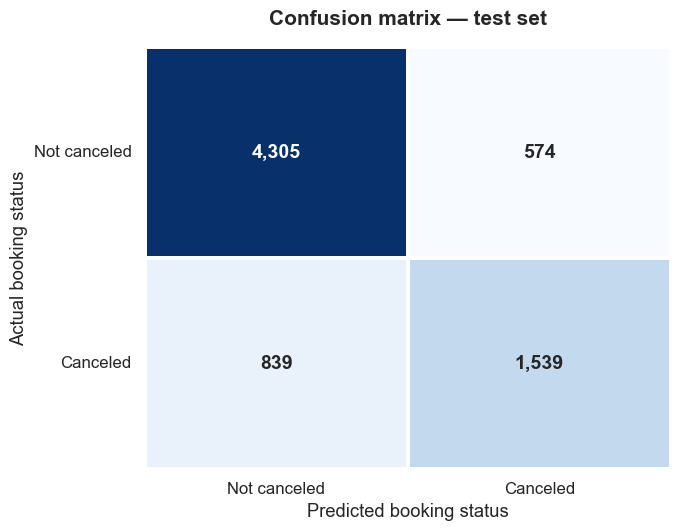

In [65]:
cm = confusion_matrix(y_test, test_predictions)

fig, ax = plt.subplots(figsize=(7, 5.5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    linewidths=1.5,
    linecolor="white",
    xticklabels=["Not canceled", "Canceled"],
    yticklabels=["Not canceled", "Canceled"],
    cbar=False,
    annot_kws={"fontsize": 14, "fontweight": "bold"},
    ax=ax
)

ax.set_title(
    "Confusion matrix — test set",
    fontsize=15, fontweight="bold", pad=16
)
ax.set_xlabel("Predicted booking status")
ax.set_ylabel("Actual booking status")
ax.tick_params(axis="both", rotation=0)

plt.tight_layout()
plt.show()


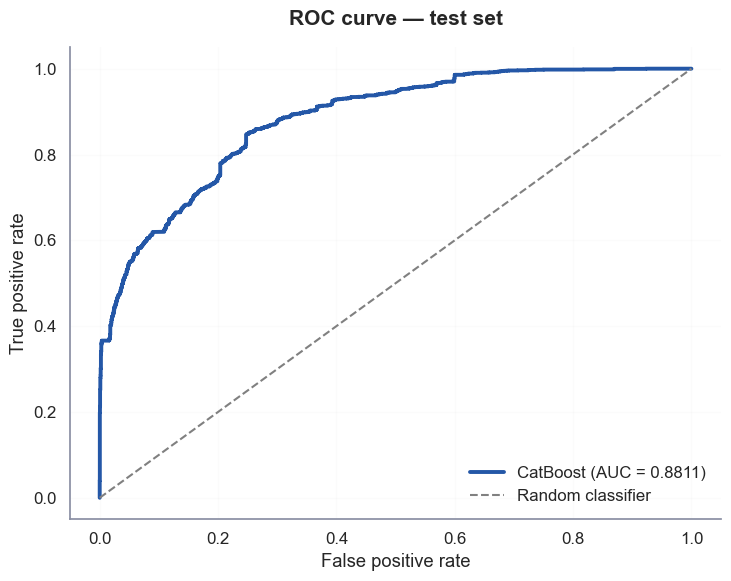

In [66]:
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
roc_auc = roc_auc_score(y_test, test_probabilities)

fig, ax = plt.subplots(figsize=(7.5, 6))

ax.plot(
    fpr, tpr,
    color="#2457A7",
    linewidth=2.8,
    label=f"CatBoost (AUC = {roc_auc:.4f})"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Random classifier"
)

ax.set_title(
    "ROC curve — test set",
    fontsize=15, fontweight="bold", pad=16
)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


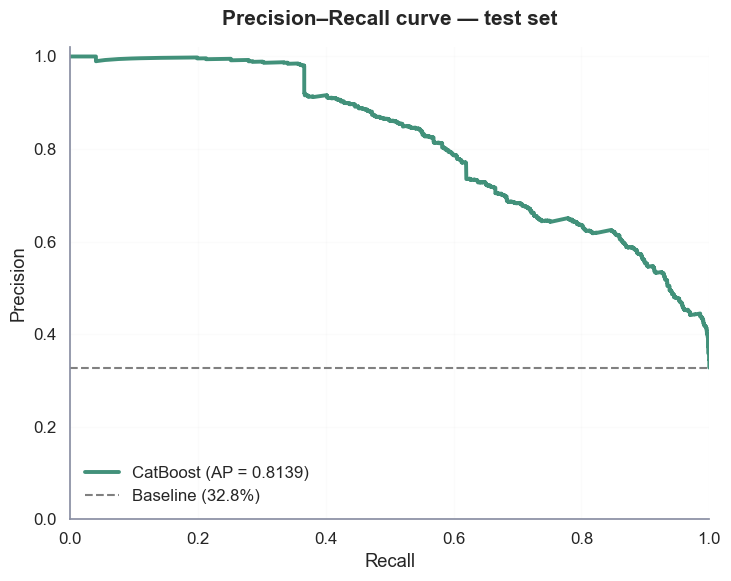

In [67]:
precision, recall, thresholds = precision_recall_curve(
    y_test, test_probabilities
)

pr_auc = average_precision_score(y_test, test_probabilities)
baseline = np.mean(y_test)

fig, ax = plt.subplots(figsize=(7.5, 6))

ax.plot(
    recall, precision,
    color="#42917A",
    linewidth=2.8,
    label=f"CatBoost (AP = {pr_auc:.4f})"
)

ax.axhline(
    baseline,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline ({baseline:.1%})"
)

ax.set_title(
    "Precision–Recall curve — test set",
    fontsize=15, fontweight="bold", pad=16
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="lower left")
ax.grid(alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


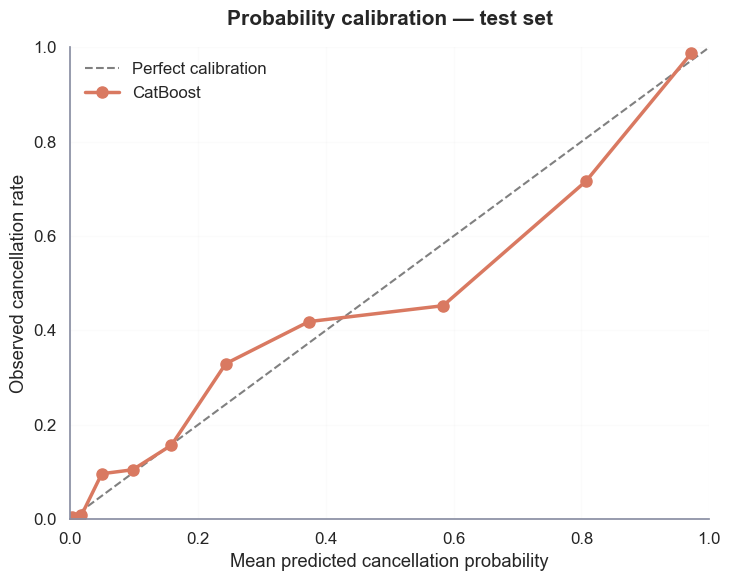

In [68]:
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_probabilities,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7.5, 6))

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Perfect calibration"
)

ax.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="#D97961",
    label="CatBoost"
)

ax.set_title(
    "Probability calibration — test set",
    fontsize=15, fontweight="bold", pad=16
)
ax.set_xlabel("Mean predicted cancellation probability")
ax.set_ylabel("Observed cancellation rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.grid(alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


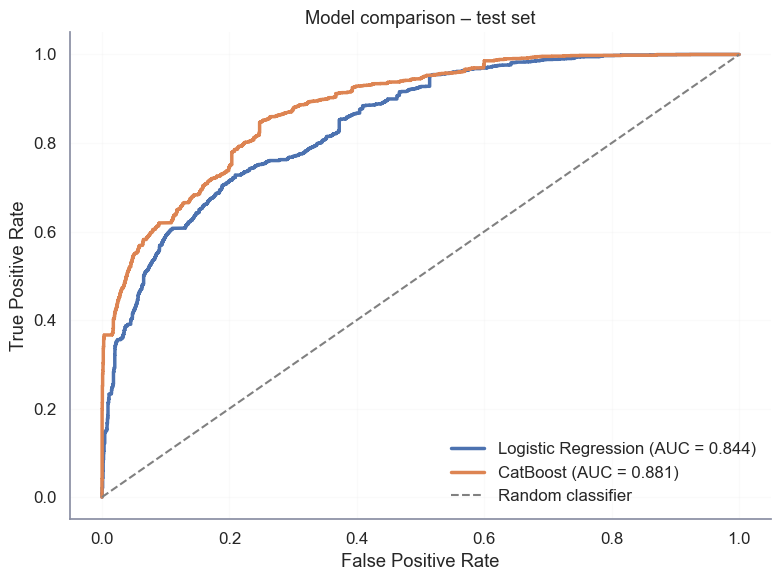

In [69]:

plt.figure(figsize=(8, 6))

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        linewidth=2.5,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Model comparison – test set")
plt.legend(frameon=False)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


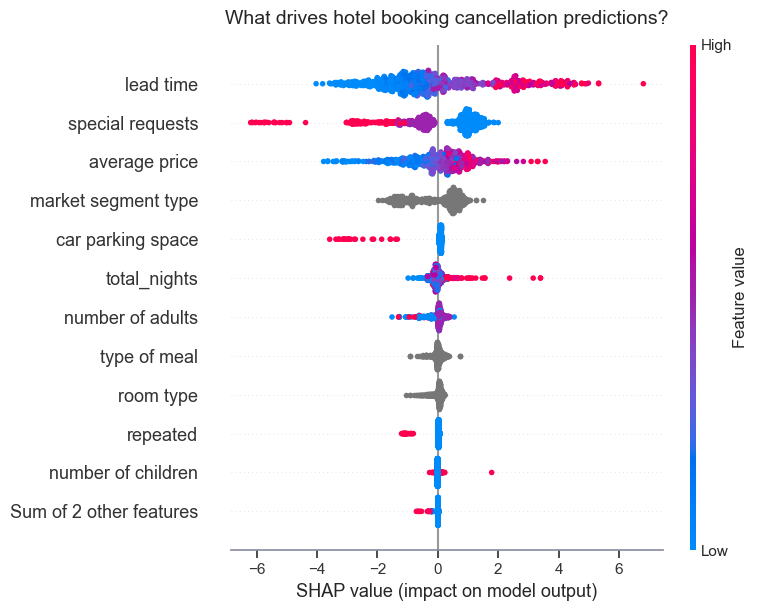

In [70]:

import shap
import matplotlib.pyplot as plt

# Select a sample of unseen test observations
X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

# Explain the existing CatBoost model
explainer = shap.TreeExplainer(catboost_model)
shap_values = explainer(X_shap)

# SHAP beeswarm plot
plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values,
    max_display=12,
    show=False
)

plt.title(
    "What drives hotel booking cancellation predictions?",
    fontsize=14,
    pad=15
)

plt.tight_layout()
plt.show()


In [71]:

# Compare both models on the same untouched test set

models = {
    "Logistic Regression": logistic_model,
    "CatBoost": catboost_model
}

results = []

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

test_comparison = pd.DataFrame(results)

display(test_comparison.round(4))


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8443,0.7423,0.7985,0.7408,0.5925,0.6584
1,CatBoost,0.8811,0.8139,0.8053,0.7283,0.6472,0.6854


# Hotel Booking Cancellations — Project Overview

## 1. Project Objective

The main objective of this project is to investigate **which factors are associated with hotel booking cancellations** and whether we can predict the probability of cancellation based on booking characteristics.

The project is not only about building an accurate machine learning model. Our main focus is on **understanding the data, identifying meaningful patterns, and investigating four research hypotheses**.

The analysis consists of three main stages:

1. **Exploratory Data Analysis (EDA):** Understanding the dataset and identifying relationships between booking characteristics and cancellations.
2. **Machine Learning (CatBoost):** Building a predictive model and interpreting how different features contribute to its predictions.
3. **Hypothesis Investigation:** Using model-based analyses and visualizations to examine whether the relationships observed during EDA remain relevant when other booking characteristics are considered.

## 2. Dataset Overview

The dataset contains **36,285 hotel bookings**.

- **24,396 bookings (67.23%)** were not canceled.
- **11,889 bookings (32.77%)** were canceled.

About **37% of the rows belong to groups of identical bookings** (the largest group has 91 rows), most often in the Offline and Corporate segments, which is typical of group bookings. They are kept in the main analysis and the data are split by group, so copies of one booking never appear in both the training and the test data.

The dataset includes information such as:

- Booking lead time (days between reservation and arrival)
- Number of adults and children
- Length of stay
- Average room price
- Number of special requests
- Market segment
- Parking requirements
- Whether the guest is a returning customer
- Room and meal types

Our target variable is **booking cancellation**, indicating whether a reservation was canceled.

## 3. Key Findings from Exploratory Data Analysis

EDA helped us identify important patterns and formulate the research hypotheses.

### A. Booking lead time is strongly associated with cancellation risk

One of the clearest findings is that bookings made further in advance are canceled more frequently.

For example:

- Bookings made **0–5 days before arrival:** approximately **8.5% cancellation rate**.
- Bookings made **193–443 days before arrival:** approximately **74.4% cancellation rate**.

This suggests a strong positive relationship between booking lead time and cancellation probability.

A possible explanation is that customers booking far in advance have more time to change their plans. However, our analysis does not establish this as a causal explanation.

### B. More special requests are associated with fewer cancellations

We observed a clear decrease in cancellation rates as the number of special requests increased.

| Number of special requests | Observed cancellation rate |
|---|---:|
| 0 | 43.2% |
| 1 | 23.8% |
| 2 | 14.6% |
| 3 or more | 0% |

An important observation is that **none of the 762 bookings with three or more special requests were canceled**.

This unusual pattern should be interpreted carefully, as it may reflect characteristics of the data collection process.

One possible interpretation is that special requests indicate greater customer commitment. However, this is only a hypothesis about the underlying behavior, not a demonstrated causal effect.

### C. Lead time and special requests may interact

We also examined the relationship between booking lead time and special requests.

The EDA heatmap showed that cancellation rates differ across combinations of these two variables.

For example, among bookings made 0–17 days in advance:

- **0 requests:** 17.2% canceled.
- **1 request:** 8.1% canceled.
- **2 requests:** 1.3% canceled.

For bookings made at least 127 days in advance:

- **0 requests:** 70.8% canceled.
- **1 request:** 55.8% canceled.
- **2 requests:** 54.8% canceled.

This suggests that the relationship between special requests and cancellation risk may vary depending on booking lead time.

### D. Cancellation rates differ across market segments

We observed substantial differences between booking segments.

| Market segment | Observed cancellation rate |
|---|---:|
| Online | 36.5% |
| Offline | 30.0% |
| Corporate | 10.9% |

Corporate bookings had a particularly low cancellation rate compared with Online bookings.

We also observed that returning guests and bookings with parking requirements had lower cancellation rates.

These were interesting additional EDA findings, although they were not selected as separate research hypotheses.

## 4. Machine Learning — CatBoost

After completing EDA, we trained a **CatBoost classification model** to predict booking cancellations.

We selected CatBoost because it works well with tabular datasets, supports categorical features, and can capture nonlinear relationships and interactions between variables.

The dataset was divided into:

- **60% training set:** Used to train the model.
- **20% validation set:** Used for model selection, early stopping, and interpretation.
- **20% test set:** Reserved for final model evaluation.

The split is stratified by cancellation status and grouped by identical bookings.

### Final Model Performance

The model achieved the following results on the held-out test set:

| Metric | Test result |
|---|---:|
| ROC-AUC | **0.8816** |
| Average Precision (PR-AUC) | **0.8153** |
| Accuracy | 81.85% |
| Precision | 76.35% |
| Recall | 64.63% |
| F1-score | 0.7001 |

These results indicate that the model distinguishes canceled and non-canceled bookings effectively.

In particular, the model identifies approximately **65% of actual cancellations**, while approximately **76% of bookings predicted as canceled are indeed canceled**.

However, model performance is not the central focus of our project. We are primarily interested in **interpreting the model and using it to investigate the relationships identified during EDA**.

### Model Interpretation Techniques

We used several methods:

- **SHAP:** Measures how individual features contribute to model predictions and helps identify important predictors.
- **Partial Dependence Plots (PDP):** Show how average model predictions change when a particular feature is varied.
- **Model-based scenario analysis:** Compares predictions when selected feature values are changed while the remaining booking characteristics are kept unchanged.
- **Permutation importance:** Measures how much model performance deteriorates when the information contained in a feature is disrupted.
- **Friedman's H-statistic:** Quantifies interaction effects between features in model predictions.

## 5. Investigation of the Four Research Hypotheses

### H1 — Longer booking lead time is associated with a higher probability of cancellation

**Conclusion: Supported by the analysis.**

EDA revealed a strong increase in observed cancellation rates as booking lead time increased.

We then used a CatBoost Partial Dependence Plot to examine the relationship in model predictions.

The PDP showed a clear, nonlinear increase in predicted cancellation probability as lead time increased.

This indicates that lead time remains an important predictor when the model also considers other booking characteristics.

**Main takeaway:** Bookings made further in advance have substantially higher observed and predicted cancellation risk.

### H2 — More special requests are associated with a lower probability of cancellation

**Conclusion: Supported by the analysis.**

EDA showed that bookings with more special requests were canceled less frequently.

We investigated this relationship further using CatBoost scenario analysis.

For each scenario, we assigned the same number of special requests to the analyzed bookings while keeping their other characteristics unchanged.

The resulting average predicted cancellation probabilities were:

| Special requests | Predicted cancellation probability |
|---|---:|
| 0 | 48.0% |
| 1 | 22.6% |
| 2 | 15.4% |

The downward pattern remained visible in the model predictions.

SHAP analysis also identified special requests as one of the most influential features.

**Main takeaway:** Special requests are strongly associated with lower predicted cancellation risk, even when other booking characteristics are considered.

This is a predictive association, not proof that adding special requests would prevent cancellations.

Two cautions: none of the 762 bookings with three or more requests was canceled, which may reflect how the data were recorded (reverse causality); and without this feature the validation ROC-AUC falls from 0.899 to 0.825, so the model relies on it heavily.

### H3 — The relationship between special requests and cancellation risk varies with booking lead time

**Conclusion: Supported by the analysis, with a moderate interaction effect.**

We investigated whether the relationship between special requests and cancellation risk changes depending on booking lead time.

To examine this, we used CatBoost prediction curves for different combinations of lead time and special requests.

We also calculated **Friedman's H-statistic**, which measures the strength of feature interactions in a predictive model.

Our results were:

**H = 0.2695; H² = 0.0726**

This indicates a non-zero interaction, although it is not one of the dominant components of the model's predictions.

The prediction curves showed that the difference in cancellation risk between bookings with one and two special requests was larger for shorter lead times, reaching up to approximately 15 percentage points (around 80 days).

The difference became smaller as lead time increased and fell below 2 percentage points beyond roughly 170 days.

A likelihood-ratio test of the interaction in the logistic GLM gives chi2 = 228.7 (df = 2); because rows inside groups of identical bookings are not independent, treat this as descriptive.

**Main takeaway:** The relationship between special requests and predicted cancellation risk is not constant across different booking lead times.

### H4 — Market segment is associated with cancellation probability, even after accounting for other booking characteristics

**Conclusion: Supported by the analysis.**

EDA showed substantial differences in cancellation rates between Online, Offline, and Corporate bookings.

We then used permutation importance to examine whether market segment provides additional predictive information to CatBoost.

After randomly permuting market segment values in the validation data:

- **Original ROC-AUC:** 0.8987
- **ROC-AUC after permutation:** 0.8316
- **Performance decrease:** 0.0671

This substantial decrease indicates that market segment contributes important information to the model.

SHAP analysis also suggested that Online bookings generally contribute positively to predicted cancellation risk relative to the model's baseline, while Offline and Corporate bookings tend to contribute negatively.

**Main takeaway:** Market segment remains an important predictor of cancellation risk when other booking characteristics are considered.

**Caution:** in the scenario analysis (every validation booking assigned to a segment, other features unchanged) the model-adjusted risk of Corporate is 29.7% versus 12.1% observed, and that of Offline 18.9% versus 31.1% observed. Much of the raw difference between segments is therefore explained by other booking characteristics, and permutation importance shows how much the model relies on a feature, not how much unique information it carries. Complementary (n = 71) and Aviation (n = 22) are too small for conclusions.

## 6. Supplementary Analysis — Logistic Regression

In addition to CatBoost, we used **multivariable logistic regression (Binomial GLM)** as a complementary statistical analysis.

Logistic regression allows us to describe associations using:

- Odds ratios
- Confidence intervals
- Statistical significance (p-values)

This analysis provides an additional statistical perspective on the relationships between booking characteristics and cancellation.

However, **CatBoost remains the main model used for prediction, interpretation, and the investigation of our research hypotheses**.

## 7. Overall Conclusions

Our project shows that hotel booking cancellations are strongly associated with several booking characteristics.

The four main findings are:

1. **Booking lead time:** Longer lead times are associated with substantially higher cancellation risk.
2. **Special requests:** More special requests are associated with lower cancellation risk.
3. **Interaction effects:** The relationship between special requests and cancellation risk varies depending on booking lead time.
4. **Market segment:** Market segment provides important additional information for predicting cancellations.

All four hypotheses received support from our exploratory and model-based analyses, with the caveats noted above (special requests, market segment, non-independent rows).

Importantly, these results describe **statistical and predictive relationships rather than causal effects**.

For example, we cannot conclude that encouraging customers to add special requests would directly reduce cancellations.

## 8. Suggested Presentation Structure

A clear presentation could follow this storyline:

**Business problem → Dataset overview → EDA findings → Research hypotheses → CatBoost model → Model interpretation → Hypothesis investigation → Final conclusions**

The presentation should emphasize the visualizations and their interpretation rather than focusing excessively on machine learning performance metrics.

The most interesting narrative connects **H1, H2, and H3**:

First, we show that longer booking lead times are associated with higher cancellation risk.

Second, we demonstrate that special requests are associated with lower cancellation risk.

Third, we show that these two relationships are connected: the association between special requests and cancellation risk changes depending on lead time.

Finally, **H4** extends the analysis by demonstrating that the market segment also provides important information about cancellation behavior.

**Central message:** By combining exploratory data analysis with interpretable machine learning, we can identify meaningful patterns in hotel booking cancellations and better understand which booking characteristics are associated with higher or lower cancellation risk.